## Imports

In [1]:
# ---------------------------------------------------------
# Load all required libraries for data processing, machine
# learning, model interpretability (SHAP), and visualization.
# ---------------------------------------------------------

import pandas as pd
import numpy as np
import re

from catboost import CatBoostRegressor, Pool
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error

import shap
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.preprocessing import StandardScaler
from scipy import stats


c:\Users\pramo\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import matplotlib.pyplot as plt


In [3]:
import seaborn as sns


In [4]:
import subprocess, sys
try:
    import openpyxl
except ImportError:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'openpyxl', '-q'])
    import openpyxl


## Dataset Loading

Load Dataset

In [5]:
# ---------------------------------------------------------
# Load the main dataset from CSV into a pandas DataFrame.
# Latin-1 encoding handles special characters in literature
# sourced entries that would cause UTF-8 parse failures.
# ---------------------------------------------------------

df = pd.read_csv("composites.csv", encoding="latin-1")


## Dataset Filtering

Filtering 

In [6]:
# ---------------------------------------------------------
# Retain only electrode-mode GCD measurements with valid
# current density and capacitance in compatible SI units.
# This ensures all retained rows share a consistent protocol
# before any unit conversion or feature engineering.
# ---------------------------------------------------------
df = df[df["measurement_type"].str.lower() == "electrode"]

df = df[df["test_mode"].str.lower().str.contains("gcd", na=False)]
df = df[df["current_density_value"].notna()]

df = df[df["current_density_unit"].str.lower().str.contains(r"ma/g|a/g", na=False)]
df = df[df["capacitance_unit"].str.lower().str.contains(r"f/g|mf/g", na=False)]

print("After filtering:", len(df))


After filtering: 549


## Data Cleaning & Preprocessing

Unit Standardization

In [7]:
# ---------------------------------------------------------
# Convert current density (mA/g -> A/g) and capacitance
# (mF/g -> F/g) so that data collected from different
# publications can be processed on a consistent numerical
# scale.
# ---------------------------------------------------------

def convert_current_density(val, unit):
    if pd.isna(val): return val 
    unit = str(unit).lower()
    if "ma" in unit: return val / 1000
    elif "a" in unit: return val
    else: return np.nan

def convert_capacitance(val, unit):
    if pd.isna(val): return val
    unit = str(unit).lower()
    if "mf" in unit: return val / 1000
    elif "f" in unit: return val
    else: return np.nan

if "current_density_unit" in df.columns:
    df["current_density_value"] = df.apply(
        lambda x: convert_current_density(x["current_density_value"], x["current_density_unit"]), axis=1
    )

if "capacitance_unit" in df.columns:
    df["specific_capacitance"] = df.apply(
        lambda x: convert_capacitance(x["specific_capacitance"], x["capacitance_unit"]), axis=1
    )


Numeric cleaning

In [8]:
# ---------------------------------------------------------
# Parse numeric columns that may contain range strings
# (e.g. '10-20') by replacing them with their midpoint,
# then coerce non-numeric entries to NaN for imputation.
# ---------------------------------------------------------

numeric_cols = [
    "specific_surface_area_m2g","pore_volume_cm3g","average_pore_size_nm","ID_IG_ratio",
    "carbonization_temperature_C","activation_temperature_C","activation_ratio",
    "calcination_temperature_C","current_density_value","potential_window_V",
    "electrolyte_concentration_M","Rct_ohms","Rs_ohms","mass_loading_mgcm2","metal_loading_wt_percent"
]

def parse_range(x):
    if isinstance(x, str):#check if a value is a string 
        nums = re.findall(r"\d+\.?\d*", x)
        if len(nums) == 2:#if range take average
            return (float(nums[0]) + float(nums[1])) / 2
        elif len(nums) == 1:#if a single number ,return it as a number
            return float(nums[0])
    return x#if no number found leave it unchanged 

for col in numeric_cols:#for every numeric column apply this 
    if col in df.columns:
        df[col] = df[col].apply(parse_range)
        df[col] = pd.to_numeric(df[col], errors="coerce")
        #force numeric type (converts everything into numbers)
        #valid-->number
        #invalid-->NaN


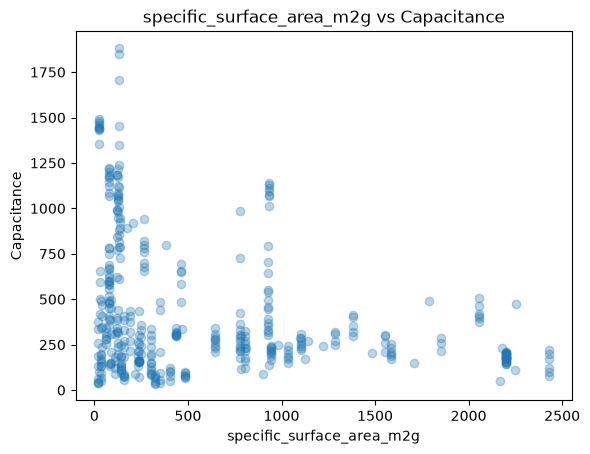

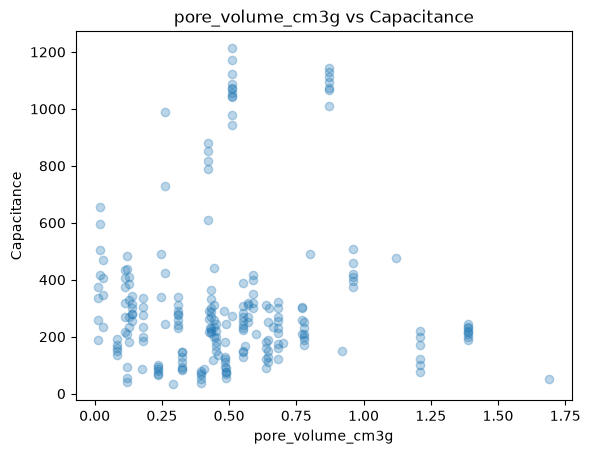

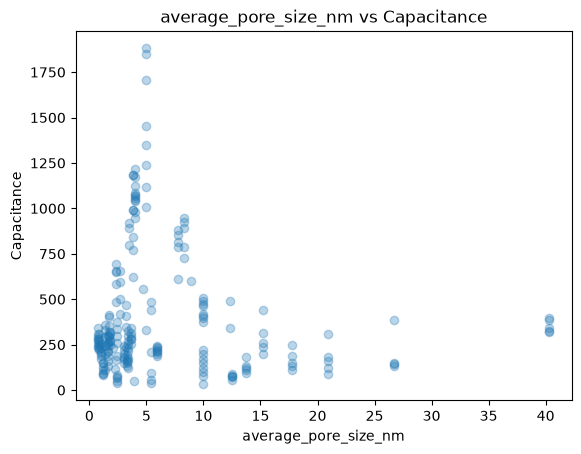

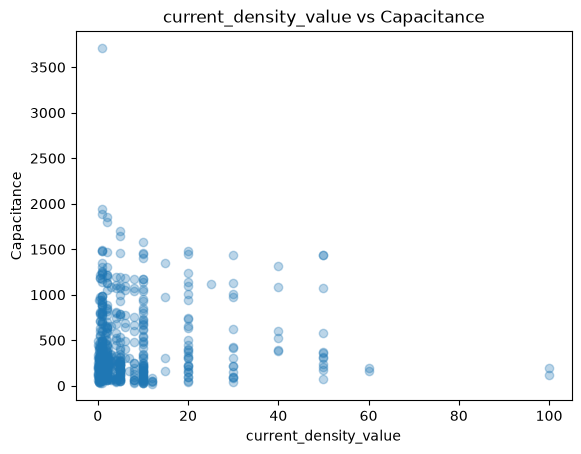

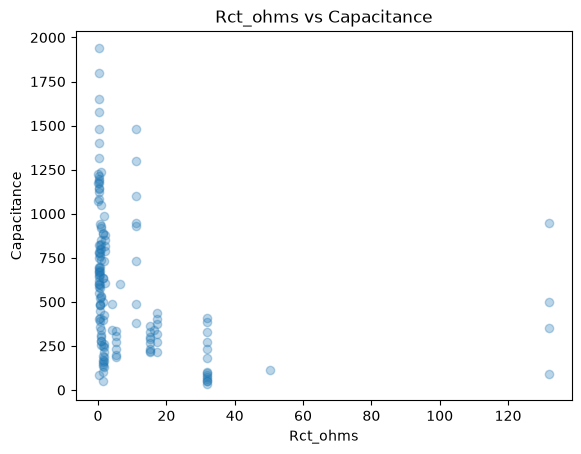

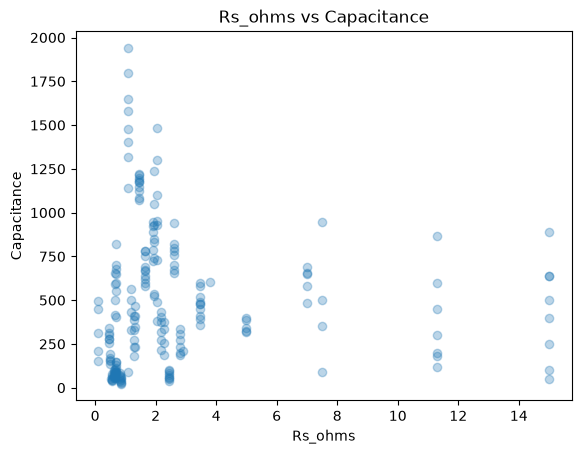

In [9]:
# ---------------------------------------------------------
# Generate scatter plots of key structural and experimental
# variables against specific capacitance to visually assess
# monotonic trends and outliers before modelling.
# ---------------------------------------------------------
columns = [
    "specific_surface_area_m2g",
    "pore_volume_cm3g",
    "average_pore_size_nm",
    "current_density_value",
    "Rct_ohms",
    "Rs_ohms"
]

for col in columns:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

for col in columns:
    if col in df.columns:
        plt.figure()
        plt.scatter(df[col], df["specific_capacitance"], alpha=0.3)
        plt.xlabel(col)
        plt.ylabel("Capacitance")
        plt.title(f"{col} vs Capacitance")
        plt.show()

Biomass Grouping

Counts:
 biomass_group
non_biomass         239
shell_based         129
soft_biomass         77
agro_residue         50
woody_structural     37
food_waste           11
protein_mineral       6
Name: count, dtype: int64

Subset length: 0

Top values:
 Series([], Name: count, dtype: int64)
Missing precursor count: 0
Total rows: 0
Counts:
 biomass_group
non_biomass         239
shell_based         129
soft_biomass         77
agro_residue         50
woody_structural     37
food_waste           11
protein_mineral       6
Name: count, dtype: int64

Percentages:
 biomass_group
non_biomass         43.533698
shell_based         23.497268
soft_biomass        14.025501
agro_residue         9.107468
woody_structural     6.739526
food_waste           2.003643
protein_mineral      1.092896
Name: count, dtype: float64


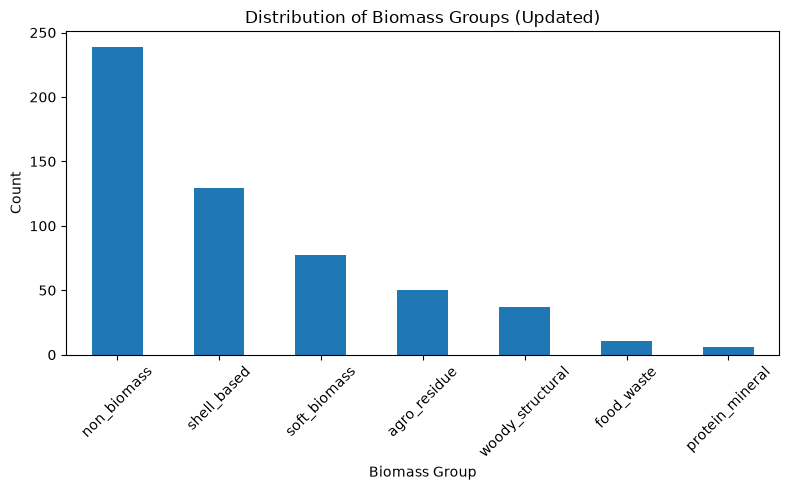

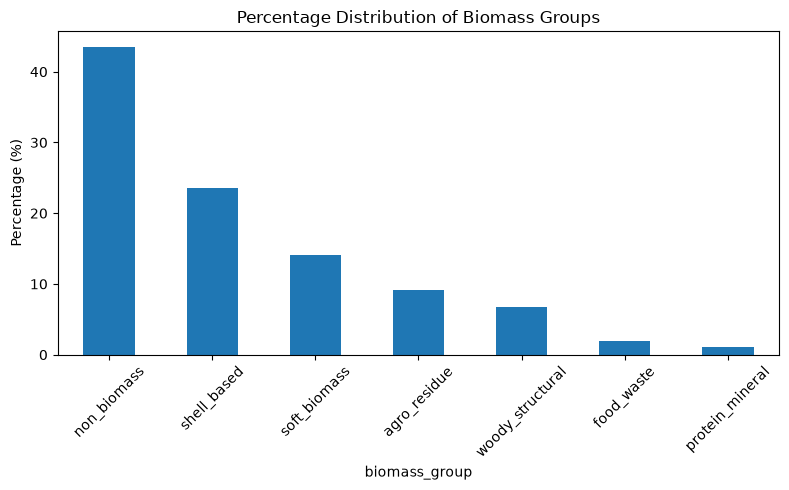

In [10]:
# ================================
# 1. Define improved grouping function
# ================================

def map_biomass_group(x):
    if pd.isna(x):
        return "non_biomass"   # ✅ correct meaning

    x = str(x).lower()

    if any(k in x for k in ["shell", "septum"]):
        return "shell_based"

    elif any(k in x for k in ["crab", "egg", "agaric", "membrane"]):
        return "protein_mineral"

    elif any(k in x for k in ["bagasse", "straw", "husk", "stalk"]):
        return "agro_residue"

    elif any(k in x for k in ["wood", "stem", "cellulose", "fiber"]):
        return "woody_structural"

    elif any(k in x for k in ["leaf", "leaves", "catkin"]):
        return "soft_biomass"

    elif any(k in x for k in ["peel", "fruit", "seed", "potato"]):
        return "food_waste"

    else:
        return "other_biomass"

# STEP 1: Recompute grouping
df["biomass_group"] = df["biomass_precursor"].apply(map_biomass_group)

df["is_biomass"] = df["biomass_precursor"].notna().astype(int)

# STEP 2: Print counts
print("Counts:\n", df["biomass_group"].value_counts())

# STEP 3: Check subset size
subset = df[df["biomass_group"] == "other_biomass"]

print("\nSubset length:", len(subset))

# STEP 4: Show top precursors
print("\nTop values:\n", subset["biomass_precursor"].value_counts().head(20))

subset = df[df["biomass_group"] == "other_biomass"]

print("Missing precursor count:", subset["biomass_precursor"].isna().sum())
print("Total rows:", len(subset))

import matplotlib.pyplot as plt

# ================================
# 1. Get counts
# ================================
counts = df["biomass_group"].value_counts()

# ================================
# 2. Print for verification
# ================================
print("Counts:\n", counts)
print("\nPercentages:\n", counts / len(df) * 100)

# ================================
# 3. Plot
# ================================
plt.figure(figsize=(8, 5))

counts.plot(kind="bar")

plt.xlabel("Biomass Group")
plt.ylabel("Count")
plt.title("Distribution of Biomass Groups (Updated)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

percent = df["biomass_group"].value_counts(normalize=True) * 100

plt.figure(figsize=(8, 5))

percent.plot(kind="bar")

plt.ylabel("Percentage (%)")
plt.title("Percentage Distribution of Biomass Groups")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Understand Electrode_configuration

In [11]:
# ================================
# 1. Raw value counts
# ================================
print("Raw counts:")
print(df["electrode_configuration"].value_counts(dropna=False))


# ================================
# 2. Percentage distribution
# ================================
print("\nPercentages:")
print(df["electrode_configuration"].value_counts(normalize=True, dropna=False) * 100)


# ================================
# 3. Unique values (very important)
# ================================
print("\nUnique values:")
print(df["electrode_configuration"].unique())

Raw counts:
electrode_configuration
three-electrode    229
three_electrode    160
3-electrode        104
two_electrode       42
3_electrode         14
Name: count, dtype: int64

Percentages:
electrode_configuration
three-electrode    41.712204
three_electrode    29.143898
3-electrode        18.943534
two_electrode       7.650273
3_electrode         2.550091
Name: proportion, dtype: float64

Unique values:
<StringArray>
['three-electrode',     '3_electrode', 'three_electrode',   'two_electrode',
     '3-electrode']
Length: 5, dtype: str


Clean Electrode_config column

In [12]:
# ---------------------------------------------------------
# Normalise electrode configuration labels by lowercasing,
# stripping whitespace, and mapping synonyms to canonical
# names (e.g. '3 electrode' -> 'three_electrode'), so the
# model receives a clean categorical feature.
# ---------------------------------------------------------
def clean_electrode_config(x):
    if pd.isna(x): 
        return "unknown"
    
    x = str(x).lower().strip().replace("_", "-")

    if "3" in x or "three" in x:
        return "three_electrode"
    elif "2" in x or "two" in x:
        return "two_electrode"
    else:
        return "other"

df["electrode_configuration"] = df["electrode_configuration"].apply(clean_electrode_config)
print(df["electrode_configuration"].value_counts())


electrode_configuration
three_electrode    507
two_electrode       42
Name: count, dtype: int64


Categorial Handling 

In [13]:
# ---------------------------------------------------------
# Standardise categorical columns (material type, electrolyte
# state, electrode configuration) by lowercasing, stripping
# whitespace, and filling missing values with 'unknown' so
# CatBoost can process them without errors.
# ---------------------------------------------------------
#clean material type
df["material_type"] = df["material_type"].astype(str).str.lower().str.strip()
df["material_type"] = df["material_type"].replace({
    "metal oxide": "metal_oxide",
    "metal_oxide": "metal_oxide",

    "metal sulfide": "metal_sulfide",
    "metal sulphide": "metal_sulfide",
    "metal_sulfide": "metal_sulfide",

    "carbon": "carbon",
    "composite": "composite"
})
print(df["material_type"].value_counts())

material_type
composite        349
carbon           132
metal_oxide       56
metal_sulfide     12
Name: count, dtype: int64


Flag Processing

In [14]:
# ---------------------------------------------------------
# Convert binary indicator (flag) columns to integers.
# These flags encode the presence or absence of processing
# steps and must be numeric for model ingestion.
# ---------------------------------------------------------
flag_cols = [
    "precursor_flag",
    "substrate_flag",
    "carbonization_flag",
    "activation_agent_flag",
    "activation_temperature_flag",
    "activation_ratio_flag",
    "metal_loading_flag",
    "calcination_flag",
    "ssa_flag",
    "pv_flag",
    "pore_flag",
    "Rct_flag",
    "Rs_flag",
    "ID_IG_flag",
    "cd_flag"
]

measured_cols, applicability_cols = [], []



for col in flag_cols:
    col_lower = df[col].astype(str).str.lower()

    # 1. Applicability
    df[col.replace("_flag", "_applicable")] = col_lower.apply(
        lambda x: 0 if x == "not_applicable" else 1
    )

    # 2. Measured
    df[col.replace("_flag", "_measured")] = col_lower.apply(
        lambda x: 1 if x == "measured" else 0
    )

    measured_cols.append(col.replace("_flag", "_measured"))
    applicability_cols.append(col.replace("_flag", "_applicable"))

df = df.drop(columns=flag_cols)

In [15]:
# ---------------------------------------------------------
# Sanity check: verify that 'biomass_group' was created and
# print all column names to confirm the expected feature set
# is present before proceeding to feature engineering.
# ---------------------------------------------------------
print("biomass_group" in df.columns)
print(df.columns.tolist())

True
['ï»¿record_id', 'doi', 'material_name', 'material_type', 'device_type', 'biomass_precursor', 'carbon_substrate', 'carbonization_temperature_C', 'activation_present', 'activation_agent', 'activation_temperature_C', 'activation_ratio', 'metal_oxide_type', 'metal_loading_wt_percent', 'mass_loading_mgcm2', 'deposition_method', 'calcination_temperature_C', 'composite_structure', 'specific_surface_area_m2g', 'pore_volume_cm3g', 'average_pore_size_nm', 'electrolyte', 'electrolyte_concentration_M', 'electrolyte_state', 'electrode_configuration', 'potential_window_V', 'test_mode', 'Scan_rate_mVs', 'scan_flag', 'Rct_ohms', 'Rs_ohms', 'resistance_origin', 'resistance_linked_to_currentdensity', 'ID_IG_ratio', 'current_density_value', 'current_density_unit', 'specific_capacitance', 'capacitance_unit', 'capacitance_comparison_possible', 'rate_retention_percent', 'rate_retention_current_density', 'capacitance_retention_percent', 'cycle_test_current_density', 'cycle_life', 'cycle_test_mode', 'en

## Composite Synergy Analysis

In [16]:
# ---------------------------------------------------------
# Compute the maximum specific capacitance per material type
# to identify which composite families achieve the highest
# performance in the dataset.
# ---------------------------------------------------------
df.groupby("material_type")["specific_capacitance"].max()

material_type
carbon            375.0
composite        3713.9
metal_oxide      1482.0
metal_sulfide    1257.0
Name: specific_capacitance, dtype: float64

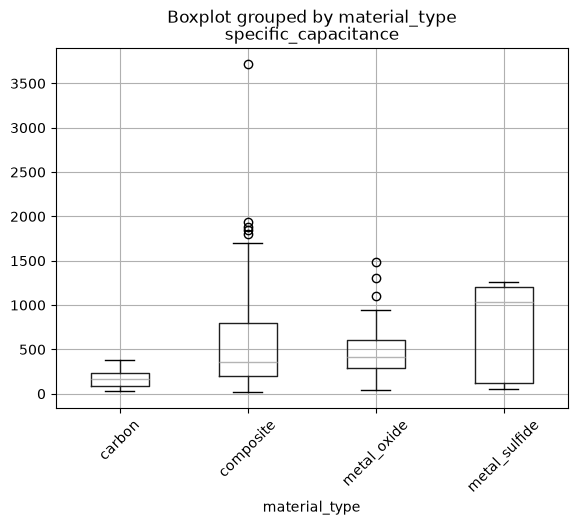

material_type
composite        349
carbon           132
metal_oxide       56
metal_sulfide     12
Name: count, dtype: int64

In [17]:
# ---------------------------------------------------------
# Visualise the capacitance distribution across material
# types with a box plot and count the number of records per
# material type to assess class balance.
# ---------------------------------------------------------

df.boxplot(column="specific_capacitance", by="material_type", rot=45)
plt.show()
df["material_type"].value_counts()

## Exploratory Data Analysis (EDA)

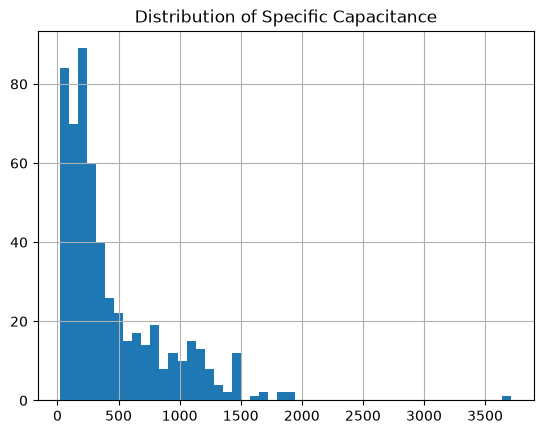

In [18]:
# ---------------------------------------------------------
# Plot the distribution of the target variable (specific
# capacitance) to check for skewness or heavy tails that
# might inform target transformation decisions.
# ---------------------------------------------------------

plt.figure()
df["specific_capacitance"].hist(bins=50)
plt.title("Distribution of Specific Capacitance")
plt.show()

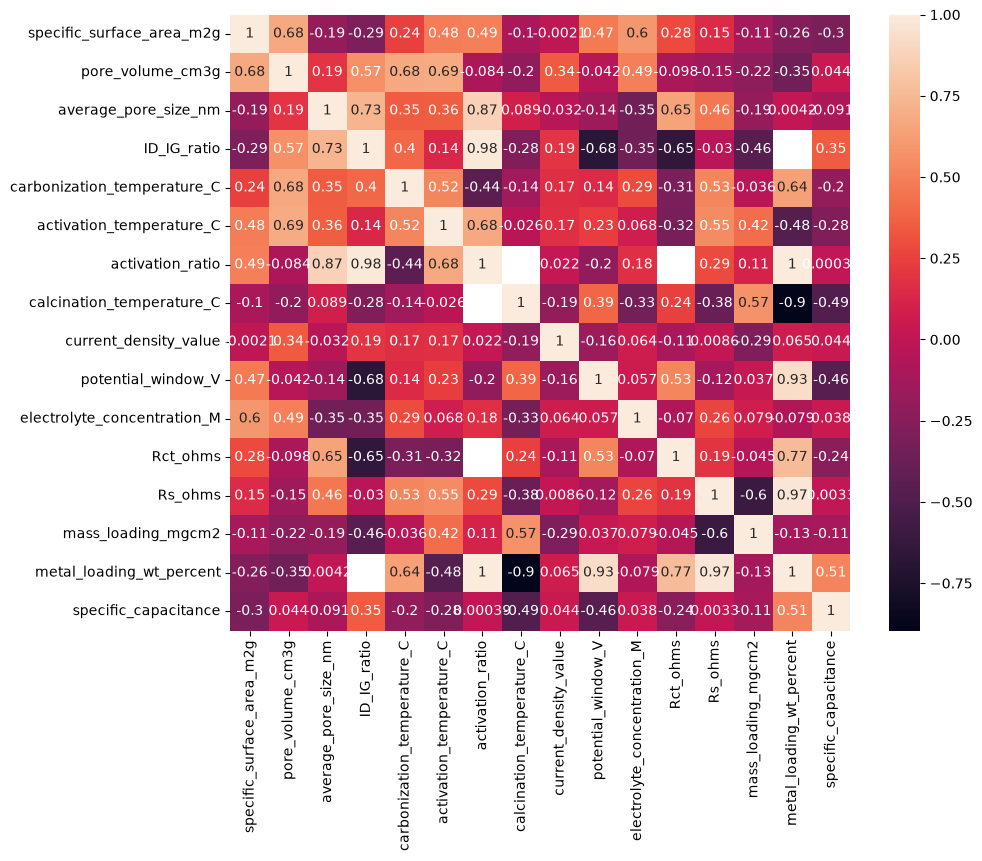

In [19]:
# ---------------------------------------------------------
# Compute and display a Pearson correlation heatmap between
# numeric input features and the target to identify strongly
# correlated predictors and potential multicollinearity.
# ---------------------------------------------------------

plt.figure(figsize=(10,8))
sns.heatmap(df[numeric_cols + ["specific_capacitance"]].corr(), annot=True)
plt.show()

EDA (TARGET DRIVEN)
everything should revolve around 
feature-->effect on capacitance

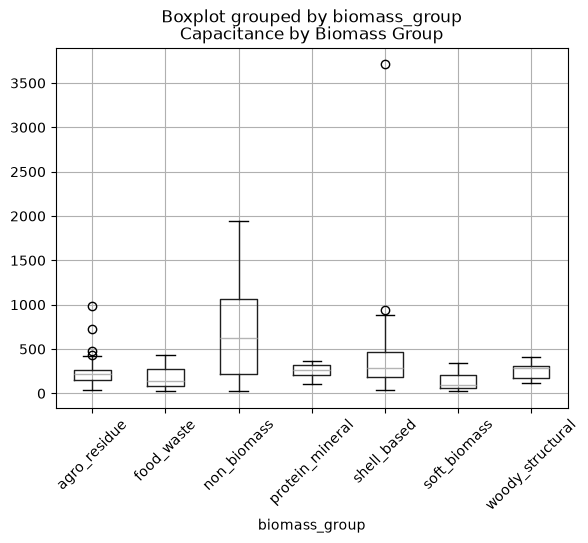

In [20]:
# ---------------------------------------------------------
# Examine how specific capacitance varies across biomass
# precursor groups, providing domain insight into which
# feedstock categories yield higher performance electrodes.
# ---------------------------------------------------------
df.boxplot(column="specific_capacitance", by="biomass_group", rot=45)
plt.title("Capacitance by Biomass Group")
plt.show()

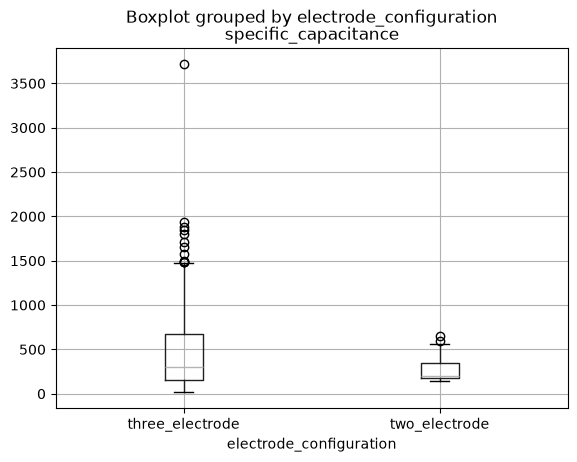

In [21]:
# ---------------------------------------------------------
# Examine specific capacitance distributions by electrode
# configuration to quantify the systematic bias introduced
# by three-electrode vs two-electrode testing protocols.
# ---------------------------------------------------------
df.boxplot(column="specific_capacitance", by="electrode_configuration")
plt.show()

In [22]:
# ---------------------------------------------------------
# Remove any duplicate columns that may have been introduced
# during merging or feature construction, then print any
# remaining duplicated column names as a sanity check.
# ---------------------------------------------------------
df = df.loc[:, ~df.columns.duplicated()]
print(df.columns[df.columns.duplicated()])

Index([], dtype='str')


## Physics-Informed Feature Engineering

Feature Engineering 

In [23]:
# ---------------------------------------------------------
# Construct physics-informed descriptors: logarithmic and
# inverse current-density transforms capture the rate-
# capability relationship; products and ratios encode
# structural synergies between surface area and pore volume.
# ---------------------------------------------------------

eps = 1e-6

df["cd_log"] = np.log1p(df["current_density_value"])
df["cd_inverse"] = 1/(df["current_density_value"]+eps)
df["voltage_squared"] = df["potential_window_V"]**2


df["ssa_pore_interaction"] = df["specific_surface_area_m2g"] * df["pore_volume_cm3g"]
df["surface_to_pore_ratio"] = df["specific_surface_area_m2g"] / (df["pore_volume_cm3g"] + eps)
df["pore_efficiency"] = df["pore_volume_cm3g"]/(df["average_pore_size_nm"]+eps)

df["structural_order_proxy"] = 1/(df["ID_IG_ratio"]+eps)

df["activation_severity"] = df["activation_temperature_C"] * df["activation_ratio"]
df["activation_pore"] = df["activation_temperature_C"] * df["average_pore_size_nm"]

df["total_resistance"] = df["Rs_ohms"] + df["Rct_ohms"]
df["conductivity_index"] = 1 / (df["total_resistance"].replace(0, np.nan) + eps)

df["cd_resistance"] = df["current_density_value"] * df["total_resistance"]
df["cd_surface"] = df["current_density_value"] * df["specific_surface_area_m2g"]

df["carbonization_scaled"] = df["carbonization_temperature_C"]/1000

df["log_Rct"] = np.log1p(df["Rct_ohms"])
df["log_Rs"] = np.log1p(df["Rs_ohms"])
df["log_total_resistance"] = np.log1p(df["total_resistance"])

df["voltage_electrolyte"] = df["potential_window_V"] * df["electrolyte_concentration_M"]

df["is_three_electrode"] = df["electrode_configuration"].str.contains("3", na=False).astype(int)



STRUCTURE + REGIME

In [24]:
# ---------------------------------------------------------
# Extract binary structural flags (metal-oxide presence,
# hierarchical porosity, heteroatom doping) from raw text
# fields and define regime-based interaction features that
# capture nonlinear performance thresholds.
# ---------------------------------------------------------


def extract_structure_features(x):
    x = str(x).lower()
    return pd.Series({
        "has_metal_oxide": int("oxide" in x),
        "has_sulfide": int("sulfide" in x),
        "has_graphene": int("graphene" in x),
        "has_cnt": int("cnt" in x)
    })

structure_features = df["composite_structure"].apply(extract_structure_features)

for col in structure_features.columns:
    df[col] = structure_features[col]

# MATERIAL-TYPE REGIME 

df["is_carbon"] = (df["material_type"] == "carbon").astype(int)
df["is_composite"] = (df["material_type"] == "composite").astype(int)
df["is_metal_oxide"] = (df["material_type"] == "metal_oxide").astype(int)
df["is_metal_sulfide"] = (df["material_type"] == "metal_sulfide").astype(int)

# COMBINED PSEUDOCAPACITIVE LOGIC

df["is_pseudocapacitive"] = (
    (df["is_metal_oxide"] == 1) |
    (df["is_metal_sulfide"] == 1) |
    (df["has_metal_oxide"] == 1) |
    (df["has_sulfide"] == 1)
).astype(int)


# INTERACTION FEATURES

df["ssa_carbon_effect"] = df["specific_surface_area_m2g"] * df["is_carbon"]
df["ssa_composite_effect"] = df["specific_surface_area_m2g"] * df["is_composite"]
df["ssa_oxide_effect"] = df["specific_surface_area_m2g"] * df["is_metal_oxide"]
df["ssa_sulfide_effect"] = df["specific_surface_area_m2g"] * df["is_metal_sulfide"]
df["ssa_biomass_effect"] = df["specific_surface_area_m2g"] * df["is_biomass"]
df["pore_biomass_effect"] = df["pore_volume_cm3g"] * df["is_biomass"]

df["pseudo_effect"] = df["conductivity_index"] * df["is_pseudocapacitive"]
df["resistance_composite"] = df["total_resistance"] * df["is_pseudocapacitive"]


# Train/Test Preparation


 FINAL FEATURES


In [25]:
# ---------------------------------------------------------
# Define the final categorical and numerical feature lists
# used for model training. All prior preprocessing and
# engineering steps feed into these feature sets.
# ---------------------------------------------------------

categorical_features = [
    "biomass_precursor","biomass_group","activation_agent",
    "electrolyte","electrolyte_state","material_type","electrode_configuration"
]

for col in categorical_features:
    if col in df.columns:
        df[col] = df[col].astype(str).fillna("unknown")


In [26]:
# ---------------------------------------------------------
# Combine numerical and categorical feature lists into one
# master feature vector and define the prediction target
# (specific capacitance in F/g) for all downstream models.
# ---------------------------------------------------------

TARGET = "specific_capacitance"

# =========================
# NUMERICAL FEATURES
# =========================

numerical_features = [

    # --- Original physical features ---
    "specific_surface_area_m2g",
    "pore_volume_cm3g",
    "average_pore_size_nm",
    "ID_IG_ratio",
    "carbonization_temperature_C",
    "activation_temperature_C",
    "activation_ratio",
    "calcination_temperature_C",
    "current_density_value",
    "potential_window_V",
    "electrolyte_concentration_M",
    "Rct_ohms",
    "Rs_ohms",
    "metal_loading_wt_percent",
    "mass_loading_mgcm2",

    # --- Transformations ---
    "cd_log",
    "cd_inverse",
    "voltage_squared",
    "carbonization_scaled",

    # --- Resistance features ---
    "total_resistance",
    "conductivity_index",
    "log_Rct",
    "log_Rs",
    "log_total_resistance",

    # --- Structural / electrochemical ---
    "structural_order_proxy",
    "activation_severity",
    "activation_pore",

    # --- Interaction features (core physics) ---
    "ssa_pore_interaction",
    "surface_to_pore_ratio",
    "pore_efficiency",
    "cd_resistance",
    "cd_surface",
    "voltage_electrolyte",

    # --- Material regime flags ---
    "is_carbon",
    "is_composite",
    "is_metal_oxide",
    "is_metal_sulfide",
    "is_pseudocapacitive",
    "is_three_electrode",

    # --- Interaction with material types ---
    "ssa_carbon_effect",
    "ssa_composite_effect",
    "ssa_oxide_effect",
    "ssa_sulfide_effect",

    # --- Biomass interactions ---
    "ssa_biomass_effect",
    "pore_biomass_effect",

    # --- Resistance interactions ---
    "pseudo_effect",
    "resistance_composite",
]

# =========================
# ADD FLAG-DERIVED FEATURES
# =========================

numerical_features += measured_cols
numerical_features += applicability_cols


# =========================
# CATEGORICAL FEATURES
# =========================

categorical_features = [
    "biomass_group",
    "material_type",
    "electrode_configuration",
    "electrolyte",
    "electrolyte_state",
    "activation_agent"
]


# =========================
# FINAL FEATURE SET
# =========================

all_features = numerical_features + categorical_features


# =========================
# FINAL CLEANING
# =========================

# Drop rows without target
df = df.dropna(subset=[TARGET])



In [27]:
# ---------------------------------------------------------
# Print the number of unique values for each categorical
# feature to verify that cardinality is manageable and that
# no unintended high-cardinality columns have been included.
# ---------------------------------------------------------
for col in categorical_features:
    print(col, df[col].nunique())

biomass_group 7
material_type 4
electrode_configuration 2
electrolyte 2
electrolyte_state 2
activation_agent 7



 GLOBAL SPLIT


In [28]:
# ---------------------------------------------------------
# Perform a stratified 80/20 train-test split at the global
# level. The held-out test set is used consistently across
# all baseline and CatBoost random-split evaluations.
# ---------------------------------------------------------
X_full = df[all_features]
y_full = df[TARGET]

# Split 20% for test
X_temp, X_test_full, y_temp, y_test_full = train_test_split(
    X_full, y_full, test_size=0.2, random_state=42
)

# Split remaining 80% into 65% Train and 15% Calibration (15/80 = 0.1875)
X_train_full, X_cal_full, y_train_full, y_cal_full = train_test_split(
    X_temp, y_temp, test_size=0.1875, random_state=42
)

print(f"Random Split -> Train: {len(X_train_full)}, Calib: {len(X_cal_full)}, Test: {len(X_test_full)}")



Random Split -> Train: 355, Calib: 83, Test: 110


## Random Split Evaluation



 BASELINE MODELS


In [29]:
# ---------------------------------------------------------
# Train Linear Regression, Random Forest, and XGBoost
# baselines on the random split, after mean-imputing missing
# values. These benchmarks contextualise CatBoost's gains.
# ---------------------------------------------------------


X_train_base = X_train_full.copy()
X_test_base = X_test_full.copy()

for col in X_train_base.columns:
    if X_train_base[col].dtype != "object":
        X_train_base[col] = X_train_base[col].fillna(-999)
        X_test_base[col] = X_test_base[col].fillna(-999)

X_train_num = X_train_base.select_dtypes(exclude=["object"])
X_test_num = X_test_base.select_dtypes(exclude=["object"])

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_num)
X_test_scaled = scaler.transform(X_test_num)

def evaluate(model, X_tr, y_tr, X_te, y_te):
    model.fit(X_tr, y_tr)
    pred = model.predict(X_te)
    return r2_score(y_te, pred), np.sqrt(mean_squared_error(y_te, pred))

r2_lr, rmse_lr = evaluate(LinearRegression(), X_train_scaled, y_train_full, X_test_scaled, y_test_full)
r2_rf, rmse_rf = evaluate(RandomForestRegressor(n_estimators=200), X_train_num, y_train_full, X_test_num, y_test_full)
r2_xgb, rmse_xgb = evaluate(XGBRegressor(n_estimators=300), X_train_num, y_train_full, X_test_num, y_test_full)



 CATBOOST OPTIMIZED MODEL


In [30]:
# ---------------------------------------------------------
# Train and evaluate the CatBoost model using the random
# train-test split to establish baseline predictive
# performance before DOI-wise cross-paper validation.
# ---------------------------------------------------------


cat_cols = [c for c in categorical_features if c in X_train_full.columns]
cat_idx = [X_train_full.columns.get_loc(c) for c in cat_cols]

train_pool = Pool(X_train_full, y_train_full, cat_features=cat_idx)
test_pool = Pool(X_test_full, y_test_full, cat_features=cat_idx)

model = CatBoostRegressor(
    iterations=3000,              
    depth=6,
    learning_rate=0.03,           
    l2_leaf_reg=5,                
    random_strength=1,
    bagging_temperature=1,
    border_count=128,
    
    loss_function="RMSE",
    eval_metric="R2",
    
    early_stopping_rounds=100,   
    random_seed=42,
    
    verbose=100
)

model.fit(train_pool, eval_set=test_pool, use_best_model=True)

preds = model.predict(test_pool)

r2_cat = r2_score(y_test_full, preds)
rmse_cat = np.sqrt(mean_squared_error(y_test_full, preds))

print("\nOptimized CatBoost")
print(f"R2: {r2_cat:.4f}")
print(f"RMSE: {rmse_cat:.2f}")


0:	learn: 0.0247754	test: -0.0777687	best: -0.0777687 (0)	total: 154ms	remaining: 7m 42s
100:	learn: 0.7458928	test: 0.7397808	best: 0.7397808 (100)	total: 3.21s	remaining: 1m 32s
200:	learn: 0.8495866	test: 0.8358895	best: 0.8358895 (200)	total: 6.06s	remaining: 1m 24s
300:	learn: 0.8946913	test: 0.8778005	best: 0.8778005 (300)	total: 8.97s	remaining: 1m 20s
400:	learn: 0.9219385	test: 0.8913384	best: 0.8917194 (391)	total: 11.9s	remaining: 1m 16s
500:	learn: 0.9411273	test: 0.8998821	best: 0.8998821 (500)	total: 14.8s	remaining: 1m 13s
600:	learn: 0.9534403	test: 0.9042571	best: 0.9042571 (600)	total: 17.6s	remaining: 1m 10s
700:	learn: 0.9609358	test: 0.9057367	best: 0.9057367 (700)	total: 20.5s	remaining: 1m 7s
800:	learn: 0.9681631	test: 0.9096946	best: 0.9096946 (800)	total: 23.3s	remaining: 1m 3s
900:	learn: 0.9730950	test: 0.9119839	best: 0.9121311 (895)	total: 29.4s	remaining: 1m 8s
1000:	learn: 0.9770149	test: 0.9146781	best: 0.9146781 (1000)	total: 39.2s	remaining: 1m 18s
11



 RESULTS


In [31]:
# ---------------------------------------------------------
# Compile R², RMSE, and MAE for all four models into a
# summary table so that CatBoost's advantage over baselines
# can be assessed on a common evaluation set.
# ---------------------------------------------------------

results = pd.DataFrame({
    "Model": ["Linear","RF","XGB","CatBoost"],
    "R2": [r2_lr, r2_rf, r2_xgb, r2_cat],
    "RMSE": [rmse_lr, rmse_rf, rmse_xgb, rmse_cat]
})

print(results.sort_values(by="R2", ascending=False))


      Model        R2        RMSE
2       XGB  0.941671   78.554429
3  CatBoost  0.929749   86.209682
1        RF  0.919587   92.234399
0    Linear -1.663422  530.823542


## DOI Group Split Evaluation

CROSS PAPER VALIDATION

In [32]:
# ---------------------------------------------------------
# Perform a DOI-grouped (paper-wise) shuffle split so that
# all measurements from the same publication appear in the
# same fold. This tests true cross-paper generalisation
# rather than memorisation of within-study variance.
# ---------------------------------------------------------
from sklearn.model_selection import GroupShuffleSplit

print("\n--- Group Split (DOI-wise) Evaluation ---")

groups = df["doi"]

# 1. Split 20% for test
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
for train_idx_temp, test_idx in gss.split(X_full, y_full, groups):
    pass

X_temp_g = X_full.iloc[train_idx_temp]
y_temp_g = y_full.iloc[train_idx_temp]
groups_temp = groups.iloc[train_idx_temp]

# 2. Split remaining 80% into 65% Train and 15% Calibration
gss_cal = GroupShuffleSplit(n_splits=1, test_size=0.1875, random_state=42)
for train_idx_rel, calib_idx_rel in gss_cal.split(X_temp_g, y_temp_g, groups_temp):
    pass

X_train_g = X_temp_g.iloc[train_idx_rel]
y_train_g = y_temp_g.iloc[train_idx_rel]
X_cal_g = X_temp_g.iloc[calib_idx_rel]
y_cal_g = y_temp_g.iloc[calib_idx_rel]
X_test_g = X_full.iloc[test_idx]
y_test_g = y_full.iloc[test_idx]

print(f"DOI Split -> Train: {len(X_train_g)}, Calib: {len(X_cal_g)}, Test: {len(X_test_g)}")
print(f"DOI Count -> Train: {groups_temp.iloc[train_idx_rel].nunique()}, Calib: {groups_temp.iloc[calib_idx_rel].nunique()}, Test: {groups.iloc[test_idx].nunique()}")

# Copy base preprocessing (Train)
X_train_base_g = X_train_g.copy()
X_test_base_g = X_test_g.copy()

for col in X_train_base_g.columns:
    if X_train_base_g[col].dtype != "object":
        X_train_base_g[col] = X_train_base_g[col].fillna(-999)
        X_test_base_g[col] = X_test_base_g[col].fillna(-999)

X_train_num_g = X_train_base_g.select_dtypes(exclude=["object"])
X_test_num_g = X_test_base_g.select_dtypes(exclude=["object"])

# Scaling (only for linear)
scaler_g = StandardScaler()
X_train_scaled_g = scaler_g.fit_transform(X_train_num_g)
X_test_scaled_g = scaler_g.transform(X_test_num_g)




--- Group Split (DOI-wise) Evaluation ---
DOI Split -> Train: 348, Calib: 105, Test: 95
DOI Count -> Train: 24, Calib: 6, Test: 8


In [33]:
# =========================================================
# DOI-GROUPED SPLIT & MODEL TRAINING
# We train model_g on a DOI-grouped split to evaluate generalisation
# in External Validation and Uncertainty Quantification.
# =========================================================
from sklearn.model_selection import GroupShuffleSplit
from catboost import Pool, CatBoostRegressor
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np

groups = df["doi"]

# Step 2a: hold out 20% of DOIs as test
gss_test = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
train_cal_idx, test_g_idx = next(gss_test.split(X_full, y_full, groups))

X_train_cal_g = X_full.iloc[train_cal_idx]
y_train_cal_g = y_full.iloc[train_cal_idx]
groups_train_cal = groups.iloc[train_cal_idx]

X_test_g  = X_full.iloc[test_g_idx]
y_test_g  = y_full.iloc[test_g_idx]

# Step 2b: split remaining 80% into 65% train / 15% calibration
gss_cal = GroupShuffleSplit(n_splits=1, test_size=0.1875, random_state=42)
train_g_idx, cal_g_idx = next(gss_cal.split(
    X_train_cal_g, y_train_cal_g, groups_train_cal
))

X_train_g = X_train_cal_g.iloc[train_g_idx]
y_train_g = y_train_cal_g.iloc[train_g_idx]

X_cal_g = X_train_cal_g.iloc[cal_g_idx]
y_cal_g = y_train_cal_g.iloc[cal_g_idx]

print(f"DOI Split → Train: {len(X_train_g)}, Calib: {len(X_cal_g)}, Test: {len(X_test_g)}")

# Step 2c: train a DOI-split CatBoost model
cat_cols_idx_g = [
    X_train_g.columns.get_loc(c)
    for c in categorical_features if c in X_train_g.columns
]

train_pool_g = Pool(X_train_g, y_train_g, cat_features=cat_cols_idx_g)
test_pool_g  = Pool(X_test_g,  y_test_g,  cat_features=cat_cols_idx_g)

model_g = CatBoostRegressor(
    iterations=3000, depth=6, learning_rate=0.03,
    l2_leaf_reg=5, random_strength=1, bagging_temperature=1,
    border_count=128, loss_function="RMSE", eval_metric="R2",
    early_stopping_rounds=100, random_seed=42, verbose=100
)
model_g.fit(train_pool_g, eval_set=test_pool_g, use_best_model=True)

preds_g  = model_g.predict(test_pool_g)
r2_cat_g   = r2_score(y_test_g, preds_g)
rmse_cat_g = np.sqrt(mean_squared_error(y_test_g, preds_g))

print(f"\nDOI-Split CatBoost → R²: {r2_cat_g:.4f} | RMSE: {rmse_cat_g:.2f} F/g")


DOI Split → Train: 348, Calib: 105, Test: 95
0:	learn: 0.0288967	test: -0.2190536	best: -0.2190536 (0)	total: 26.1ms	remaining: 1m 18s
100:	learn: 0.7580807	test: 0.1446232	best: 0.1497223 (93)	total: 4.12s	remaining: 1m 58s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.1497222652
bestIteration = 93

Shrink model to first 94 iterations.

DOI-Split CatBoost → R²: 0.1497 | RMSE: 495.61 F/g


## External Validation

Applies the fully trained DOI-grouped model (`model_g`) to an independent
external dataset (`Master_External_Validation_Dataset.xlsx`) that was not
seen during any stage of training, calibration, or test-set evaluation.
All preprocessing and feature engineering exactly replicate the pipeline
used on the training dataset.

In [34]:
# =========================================================
# EXTERNAL VALIDATION -- STEP 1: Load External Dataset
# =========================================================
# Load the independent external validation dataset that was
# collected from completely unseen publications. This dataset
# is used only for evaluating the finalized DOI-grouped model.

ext_raw = pd.read_excel("Master_External_Validation_Dataset.xlsx")

print(f"Loaded Master_External_Validation_Dataset.xlsx: shape {ext_raw.shape}")
print(f"Columns: {ext_raw.columns.tolist()}")

Loaded Master_External_Validation_Dataset.xlsx: shape (31, 68)
Columns: ['record_id', 'doi', 'material_name', 'material_type', 'device_type', 'biomass_precursor', 'precursor_flag', 'carbon_substrate', 'substrate_flag', 'carbonization_temperature_C', 'carbonization_flag', 'activation_present', 'activation_agent', 'activation_agent_flag', 'activation_temperature_C', 'activation_temperature_flag', 'activation_ratio', 'activation_ratio_flag', 'metal_oxide_type', 'metal_loading_wt_percent', 'metal_loading_flag', 'mass_loading_mgcm2', 'deposition_method', 'calcination_temperature_C', 'calcination_flag', 'composite_structure', 'specific_surface_area_m2g', 'ssa_flag', 'pore_volume_cm3g', 'pv_flag', 'average_pore_size_nm', 'pore_flag', 'electrolyte', 'electrolyte_concentration_M', 'electrolyte_state', 'electrode_configuration', 'potential_window_V', 'test_mode', 'Scan_rate_mVs', 'scan_flag', 'Rct_ohms', 'Rct_flag', 'Rs_ohms', 'Rs_flag', 'resistance_origin', 'resistance_linked_to_currentdensity'

In [35]:
# =========================================================
# EXTERNAL VALIDATION -- STEP 2: Preprocess External Dataset
# =========================================================
# This function replicates the EXACT preprocessing and feature-
# engineering pipeline used on the training data.
# It reuses:
#   - convert_current_density(), convert_capacitance() (defined in notebook)
#   - parse_range()                                    (defined in notebook)
#   - extract_structure_features()                     (defined in notebook)
#   - numeric_cols, flag_cols, categorical_features    (defined in notebook)
#   - TARGET, eps, all_features                        (defined in notebook)
#
# Key compatibility differences vs. training data:
#   - measurement_type / test_mode filtering is relaxed to accept
#     "electrode|gravimetric" and "gcd|galvanostatic" (external papers
#     may use slightly different wording).
#   - Flag columns may be absent or use "reported" instead of "measured".
#   - Columns absent in the external dataset are filled with NaN / 0.
# =========================================================

def apply_manuscript_preprocessing_for_validation(raw_df):
    """
    Apply the full manuscript preprocessing and feature engineering
    pipeline to an external (held-out) dataset.

    Reuses all helper functions and constants already defined in the
    notebook.  Does NOT retrain or alter any model or training split.
    """
    d = raw_df.copy()

    # --- Normalise string columns ---
    for str_col in ["measurement_type", "test_mode",
                    "current_density_unit", "capacitance_unit"]:
        if str_col in d.columns:
            d[str_col] = (d[str_col].fillna("").astype(str)
                          .str.strip().str.lower())

    # --- Relaxed filtering (accept common synonyms in external papers) ---
    if "measurement_type" in d.columns:
        d = d[
            d["measurement_type"].str.contains(
                "electrode|gravimetric", na=False
            ) | (d["measurement_type"] == "")
        ]
    if "test_mode" in d.columns:
        d = d[
            d["test_mode"].str.contains(
                "gcd|galvanostatic", na=False
            ) | (d["test_mode"] == "")
        ]
    if TARGET in d.columns:
        d = d.dropna(subset=[TARGET])

    # --- Unit conversion (reuses notebook functions) ---
    if "current_density_value" in d.columns:
        d["current_density_value"] = d.apply(
            lambda x: convert_current_density(
                x["current_density_value"],
                x.get("current_density_unit", "")
            ), axis=1
        )
    if TARGET in d.columns:
        d[TARGET] = d.apply(
            lambda x: convert_capacitance(
                x[TARGET],
                x.get("capacitance_unit", "")
            ), axis=1
        )

    # --- Numeric cleaning (reuses notebook's parse_range + numeric_cols) ---
    for col in numeric_cols:
        if col in d.columns:
            d[col] = d[col].apply(parse_range)
            d[col] = pd.to_numeric(d[col], errors="coerce")
        else:
            d[col] = np.nan   # fill missing columns with NaN

    # --- Biomass grouping ---
    def _map_biomass_group(val):
        if pd.isna(val) or str(val).lower() in [
                "nan", "none", "unknown", "not reported", ""]:
            return "non_biomass"
        v = str(val).strip().lower()
        if any(k in v for k in ["shell", "septum"]):
            return "shell_based"
        elif any(k in v for k in ["crab", "egg", "agaric", "membrane"]):
            return "protein_mineral"
        elif any(k in v for k in ["bagasse", "straw", "husk", "stalk"]):
            return "agro_residue"
        elif any(k in v for k in ["wood", "stem", "cellulose", "fiber"]):
            return "woody_structural"
        elif any(k in v for k in ["leaf", "leaves", "catkin"]):
            return "soft_biomass"
        elif any(k in v for k in ["peel", "fruit", "seed", "potato"]):
            return "food_waste"
        return "other_biomass"

    d["biomass_group"] = (
        d["biomass_precursor"].apply(_map_biomass_group)
        if "biomass_precursor" in d.columns else "non_biomass"
    )
    d["is_biomass"] = (
        d["biomass_precursor"].notna().astype(int)
        if "biomass_precursor" in d.columns else 0
    )

    # --- Electrode configuration ---
    def _clean_electrode_config(val):
        v = str(val).lower()
        if "3" in v or "three" in v:
            return "three_electrode"
        elif "2" in v or "two" in v or "symmetric" in v or "cell" in v:
            return "two_electrode"
        return "unknown"

    d["electrode_configuration"] = (
        d["electrode_configuration"].apply(_clean_electrode_config)
        if "electrode_configuration" in d.columns else "unknown"
    )

    # --- Material type normalisation ---
    if "material_type" in d.columns:
        d["material_type"] = (
            d["material_type"].fillna("composite")
            .astype(str).str.lower().str.strip()
        )
        d["material_type"] = d["material_type"].replace({
            "metal oxide":   "metal_oxide",
            "metal_oxide":   "metal_oxide",
            "metal sulfide": "metal_sulfide",
            "metal sulphide":"metal_sulfide",
            "metal_sulfide": "metal_sulfide",
            "carbon":        "carbon",
            "composite":     "composite",
        })

    # --- Fill categorical columns ---
    cat_cols_to_fill = [
        "biomass_precursor", "biomass_group", "activation_agent",
        "electrolyte", "electrolyte_state", "material_type",
        "electrode_configuration"
    ]
    for col in cat_cols_to_fill:
        if col in d.columns:
            d[col] = d[col].astype(str).fillna("unknown")
        else:
            d[col] = "unknown"

    # --- Flag columns ---
    # External datasets may use "reported" (not "measured") or omit flags.
    for col in flag_cols:
        if col in d.columns:
            col_lower = d[col].astype(str).str.lower()
            d[col.replace("_flag", "_applicable")] = col_lower.apply(
                lambda x: 0 if x in ["not_applicable", "not reported", "nan"]
                          else 1
            )
            d[col.replace("_flag", "_measured")] = col_lower.apply(
                lambda x: 1 if x in ["measured", "reported"] else 0
            )
        else:
            d[col.replace("_flag", "_applicable")] = 0
            d[col.replace("_flag", "_measured")]    = 0

    # --- Structure features (reuses notebook's extract_structure_features) ---
    if "composite_structure" in d.columns:
        struct_df = d["composite_structure"].apply(extract_structure_features)
    else:
        struct_df = pd.DataFrame(
            {"has_metal_oxide": 0, "has_sulfide": 0,
             "has_graphene": 0, "has_cnt": 0},
            index=d.index
        )

    # --- Derived numeric series (safe: fills NaN for absent columns) ---
    def _col(name):
        return d[name] if name in d.columns else pd.Series(np.nan, index=d.index)

    cd_val    = _col("current_density_value")
    pot_win   = _col("potential_window_V")
    ssa       = _col("specific_surface_area_m2g")
    pv        = _col("pore_volume_cm3g")
    pore_size = _col("average_pore_size_nm")
    id_ig     = _col("ID_IG_ratio")
    act_temp  = _col("activation_temperature_C")
    act_ratio = _col("activation_ratio")
    rs        = _col("Rs_ohms")
    rct       = _col("Rct_ohms")
    tot_res   = rs + rct
    carb_temp = _col("carbonization_temperature_C")
    elyte_conc= _col("electrolyte_concentration_M")
    mat_type  = d["material_type"] if "material_type" in d.columns else pd.Series("composite", index=d.index)
    is_bio    = d["is_biomass"]

    is_carb = (mat_type == "carbon").astype(int)
    is_comp = (mat_type == "composite").astype(int)
    is_ox   = (mat_type == "metal_oxide").astype(int)
    is_sulf = (mat_type == "metal_sulfide").astype(int)

    has_ox   = struct_df["has_metal_oxide"]
    has_sulf = struct_df["has_sulfide"]

    is_pseudo  = ((is_ox == 1) | (is_sulf == 1) | (has_ox == 1) | (has_sulf == 1)).astype(int)
    cond_idx   = 1 / (tot_res.replace(0, np.nan) + eps)

    # --- Feature engineering (mirrors training pipeline exactly) ---
    new_features = {
        "cd_log":               np.log1p(cd_val),
        "cd_inverse":           1 / (cd_val + eps),
        "voltage_squared":      pot_win ** 2,
        "ssa_pore_interaction":  ssa * pv,
        "surface_to_pore_ratio": ssa / (pv + eps),
        "pore_efficiency":       pv / (pore_size + eps),
        "structural_order_proxy": 1 / (id_ig + eps),
        "activation_severity":   act_temp * act_ratio,
        "activation_pore":       act_temp * pore_size,
        "total_resistance":      tot_res,
        "conductivity_index":    cond_idx,
        "cd_resistance":         cd_val * tot_res,
        "cd_surface":            cd_val * ssa,
        "carbonization_scaled":  carb_temp / 1000,
        "log_Rct":               np.log1p(rct),
        "log_Rs":                np.log1p(rs),
        "log_total_resistance":  np.log1p(tot_res),
        "voltage_electrolyte":   pot_win * elyte_conc,
        "is_three_electrode":    d["electrode_configuration"].astype(str)
                                   .str.contains("three|3", na=False).astype(int),
        "is_carbon":             is_carb,
        "is_composite":          is_comp,
        "is_metal_oxide":        is_ox,
        "is_metal_sulfide":      is_sulf,
        "is_pseudocapacitive":   is_pseudo,
        "ssa_carbon_effect":     ssa * is_carb,
        "ssa_composite_effect":  ssa * is_comp,
        "ssa_oxide_effect":      ssa * is_ox,
        "ssa_sulfide_effect":    ssa * is_sulf,
        "ssa_biomass_effect":    ssa * is_bio,
        "pore_biomass_effect":   pv  * is_bio,
        "pseudo_effect":         cond_idx * is_pseudo,
        "resistance_composite":  tot_res  * is_pseudo,
    }

    for col in struct_df.columns:
        new_features[col] = struct_df[col]

    ext_engineered = pd.concat(
        [d, pd.DataFrame(new_features, index=d.index)], axis=1
    ).copy()

    return ext_engineered


# Apply preprocessing + feature engineering
ext_df = apply_manuscript_preprocessing_for_validation(ext_raw).dropna(subset=[TARGET])
print(f"External dataset after preprocessing: {len(ext_df)} rows")
print(f"Features required: {len(all_features)}")

# Check for any missing features
missing_features = [f for f in all_features if f not in ext_df.columns]
if missing_features:
    print(f"WARNING -- missing features (will be NaN): {missing_features}")
else:
    print("All required features are present in the external dataset.")


External dataset after preprocessing: 31 rows
Features required: 83
All required features are present in the external dataset.


In [36]:
# =========================================================
# EXTERNAL VALIDATION -- STEP 3: Predict + Compute Metrics
# =========================================================
# Uses the already-trained DOI-grouped model (model_g) defined in
# the Uncertainty Quantification cell above. No retraining.

from sklearn.metrics import mean_absolute_error as _mae

# Build feature matrix
X_ext = ext_df[all_features].copy()
y_ext = ext_df[TARGET]

# Ensure categorical columns are string type (CatBoost requirement)
for col in categorical_features:
    if col in X_ext.columns:
        X_ext[col] = X_ext[col].astype(str)

cat_idx_ext = [
    X_ext.columns.get_loc(c)
    for c in categorical_features if c in X_ext.columns
]
ext_pool = Pool(X_ext, y_ext, cat_features=cat_idx_ext)

# Predict using model_g (DOI-grouped trained model)
pred_ext = model_g.predict(ext_pool)

# Compute metrics
r2_ext      = r2_score(y_ext, pred_ext)
rmse_ext    = np.sqrt(mean_squared_error(y_ext, pred_ext))
mae_ext     = _mae(y_ext, pred_ext)
pearson_r,  p_val  = stats.pearsonr(y_ext, pred_ext)
spearman_rho, s_pval = stats.spearmanr(y_ext, pred_ext)

print("\n" + "=" * 50)
print("  External Validation Results  (model_g)")
print("=" * 50)
print("  External rows (N)         : %d"  % len(ext_df))
print("  R2                        : %.4f" % r2_ext)
print("  RMSE (F/g)                : %.2f" % rmse_ext)
print("  MAE  (F/g)                : %.2f" % mae_ext)
print("  Pearson  r                : %.4f  (p = %.4e)" % (pearson_r, p_val))
print("  Spearman rho              : %.4f  (p = %.4e)" % (spearman_rho, s_pval))
print("=" * 50)



  External Validation Results  (model_g)
  External rows (N)         : 31
  R2                        : 0.2349
  RMSE (F/g)                : 472.20
  MAE  (F/g)                : 386.34
  Pearson  r                : 0.7120  (p = 7.0720e-06)
  Spearman rho              : 0.5515  (p = 1.2993e-03)


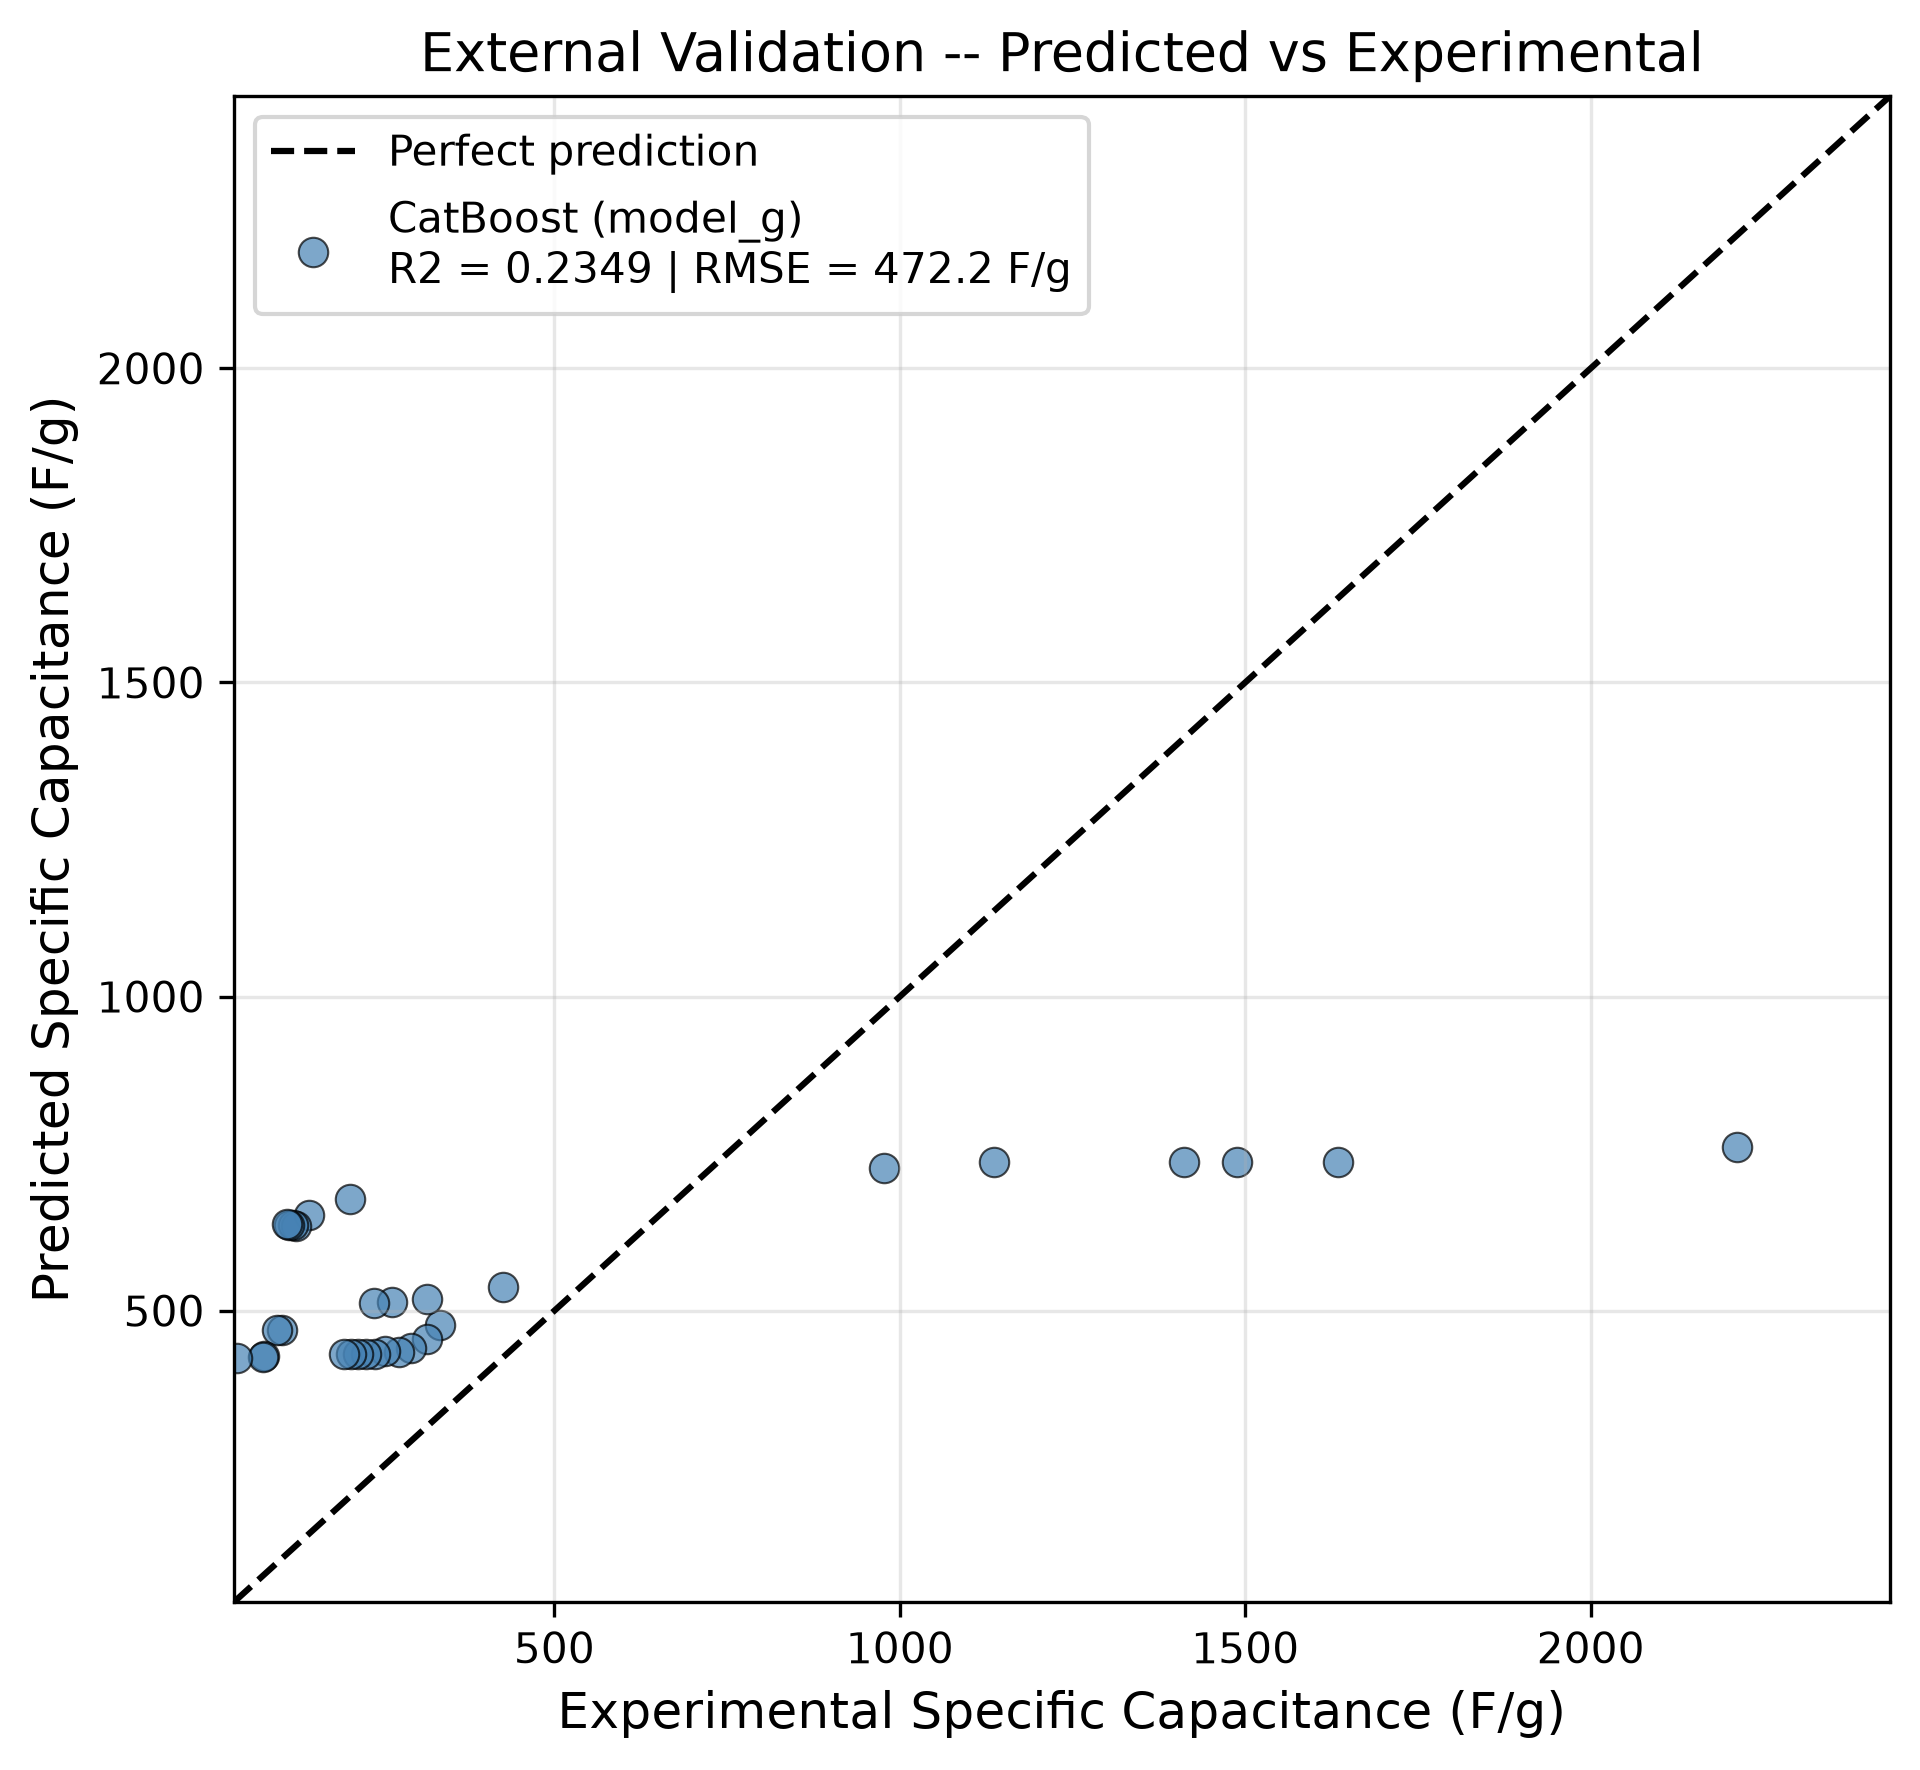

Saved: external_validation_parity_plot.png


In [37]:
# =========================================================
# EXTERNAL VALIDATION -- STEP 4: Parity Plot
# =========================================================

fig_ext, ax_ext = plt.subplots(figsize=(6.5, 6), dpi=300)

y_ext_vals   = y_ext.values
pred_ext_arr = pred_ext

lim_low  = min(y_ext_vals.min(), pred_ext_arr.min()) * 0.9
lim_high = max(y_ext_vals.max(), pred_ext_arr.max()) * 1.1
lims = [lim_low, lim_high]

ax_ext.plot(lims, lims, "k--", lw=1.5, label="Perfect prediction")
ax_ext.scatter(
    y_ext_vals, pred_ext_arr,
    alpha=0.7, edgecolor="k", linewidths=0.5,
    color="steelblue", s=50,
    label="CatBoost (model_g)\nR2 = %.4f | RMSE = %.1f F/g" % (r2_ext, rmse_ext)
)
ax_ext.set_xlim(lims)
ax_ext.set_ylim(lims)
ax_ext.set_xlabel("Experimental Specific Capacitance (F/g)", fontsize=12)
ax_ext.set_ylabel("Predicted Specific Capacitance (F/g)",   fontsize=12)
ax_ext.set_title("External Validation -- Predicted vs Experimental", fontsize=13)
ax_ext.legend(frameon=True, loc="upper left", fontsize=10)
ax_ext.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("external_validation_parity_plot.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved: external_validation_parity_plot.png")


In [38]:
# =========================================================
# EXTERNAL VALIDATION -- STEP 5: Export Results
# =========================================================

output_df = pd.DataFrame({
    "Experimental_Capacitance_Fg":      y_ext.values,
    "Predicted_Capacitance_CatBoost_Fg": pred_ext,
    "Absolute_Error":  np.abs(pred_ext - y_ext.values),
    "Percentage_Error": np.abs(
        (pred_ext - y_ext.values) / np.where(y_ext.values == 0, np.nan, y_ext.values)
    ) * 100,
})

if "doi" in ext_df.columns:
    output_df["DOI"] = ext_df["doi"].values
if "material_name" in ext_df.columns:
    output_df["Material_Name"] = ext_df["material_name"].values

output_df.to_excel("external_validation_predictions.xlsx", index=False)
print("Saved: external_validation_predictions.xlsx")
print(f"Rows exported: {len(output_df)}")
print("\n=== EXTERNAL VALIDATION COMPLETE ===")


Saved: external_validation_predictions.xlsx
Rows exported: 31

=== EXTERNAL VALIDATION COMPLETE ===


## Feature Importance

                        feature  importance
17              voltage_squared    9.306314
9            potential_window_V    6.276727
4   carbonization_temperature_C    5.968210
7     calcination_temperature_C    5.731094
62         precursor_applicable    4.439487
78                material_type    4.255626
18         carbonization_scaled    3.952059
77                biomass_group    2.746628
29              pore_efficiency    2.576047
68     metal_loading_applicable    2.486235
14           mass_loading_mgcm2    2.292856
32          voltage_electrolyte    2.271205
54         calcination_measured    2.259304
47           precursor_measured    2.039928
40         ssa_composite_effect    2.036223
8         current_density_value    1.998413
10  electrolyte_concentration_M    1.915874
22                       log_Rs    1.825725
16                   cd_inverse    1.728374
33                    is_carbon    1.664881


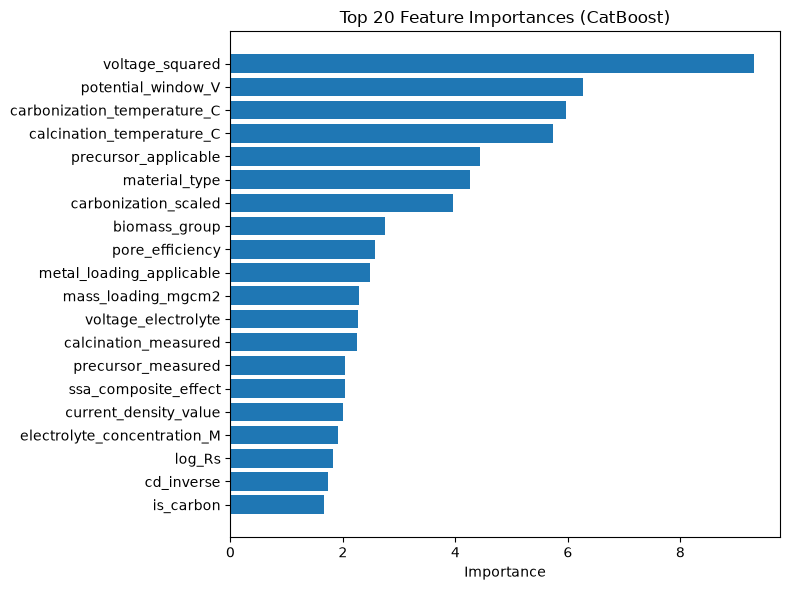

In [39]:
# ---------------------------------------------------------
# Extract CatBoost's built-in feature importance scores
# (PredictionValuesChange) and plot a ranked bar chart.
# These scores reflect each feature's contribution to
# reducing prediction error during training.
# ---------------------------------------------------------

importances = model.get_feature_importance(train_pool)

feat_imp = pd.DataFrame({
    "feature": X_train_full.columns,
    "importance": importances
}).sort_values(by="importance", ascending=False)

print(feat_imp.head(20))


# FEATURE IMPORTANCE PLOT

import matplotlib.pyplot as plt

# Get top 20 features
top_n = 20
feat_imp_top = feat_imp.head(top_n)

plt.figure(figsize=(8, 6))
plt.barh(feat_imp_top["feature"], feat_imp_top["importance"])
plt.gca().invert_yaxis()

plt.xlabel("Importance")
plt.title(f"Top {top_n} Feature Importances (CatBoost)")

plt.tight_layout()
plt.show()


## 14. Permutation Importance

To complement the model-specific feature importance obtained from CatBoost and SHAP, permutation importance was computed on the held-out DOI-grouped test set. Unlike SHAP, permutation importance is model-agnostic and quantifies the decrease in predictive performance (ΔR²) when the values of each feature are randomly permuted. This provides an independent assessment of feature relevance and validates the robustness of the identified influential descriptors.

Using model variable: 'model_g'
Using test set variables: X = 'X_test_g', y = 'y_test_g'
Resolved 83 feature names from DataFrame columns.

===== TOP 20 FEATURES BY PERMUTATION IMPORTANCE =====
                          Feature  Mean_Importance  Std_Importance
                  voltage_squared           0.0688          0.0132
         carbonization_applicable           0.0454          0.0102
               potential_window_V           0.0300          0.0104
                     is_composite           0.0251          0.0157
                        is_carbon           0.0168          0.0065
                    material_type           0.0161          0.0161
           calcination_applicable           0.0112          0.0019
      carbonization_temperature_C           0.0111          0.0064
             carbonization_scaled           0.0086          0.0069
             calcination_measured           0.0076          0.0014
        calcination_temperature_C           0.0073          0.0055
  

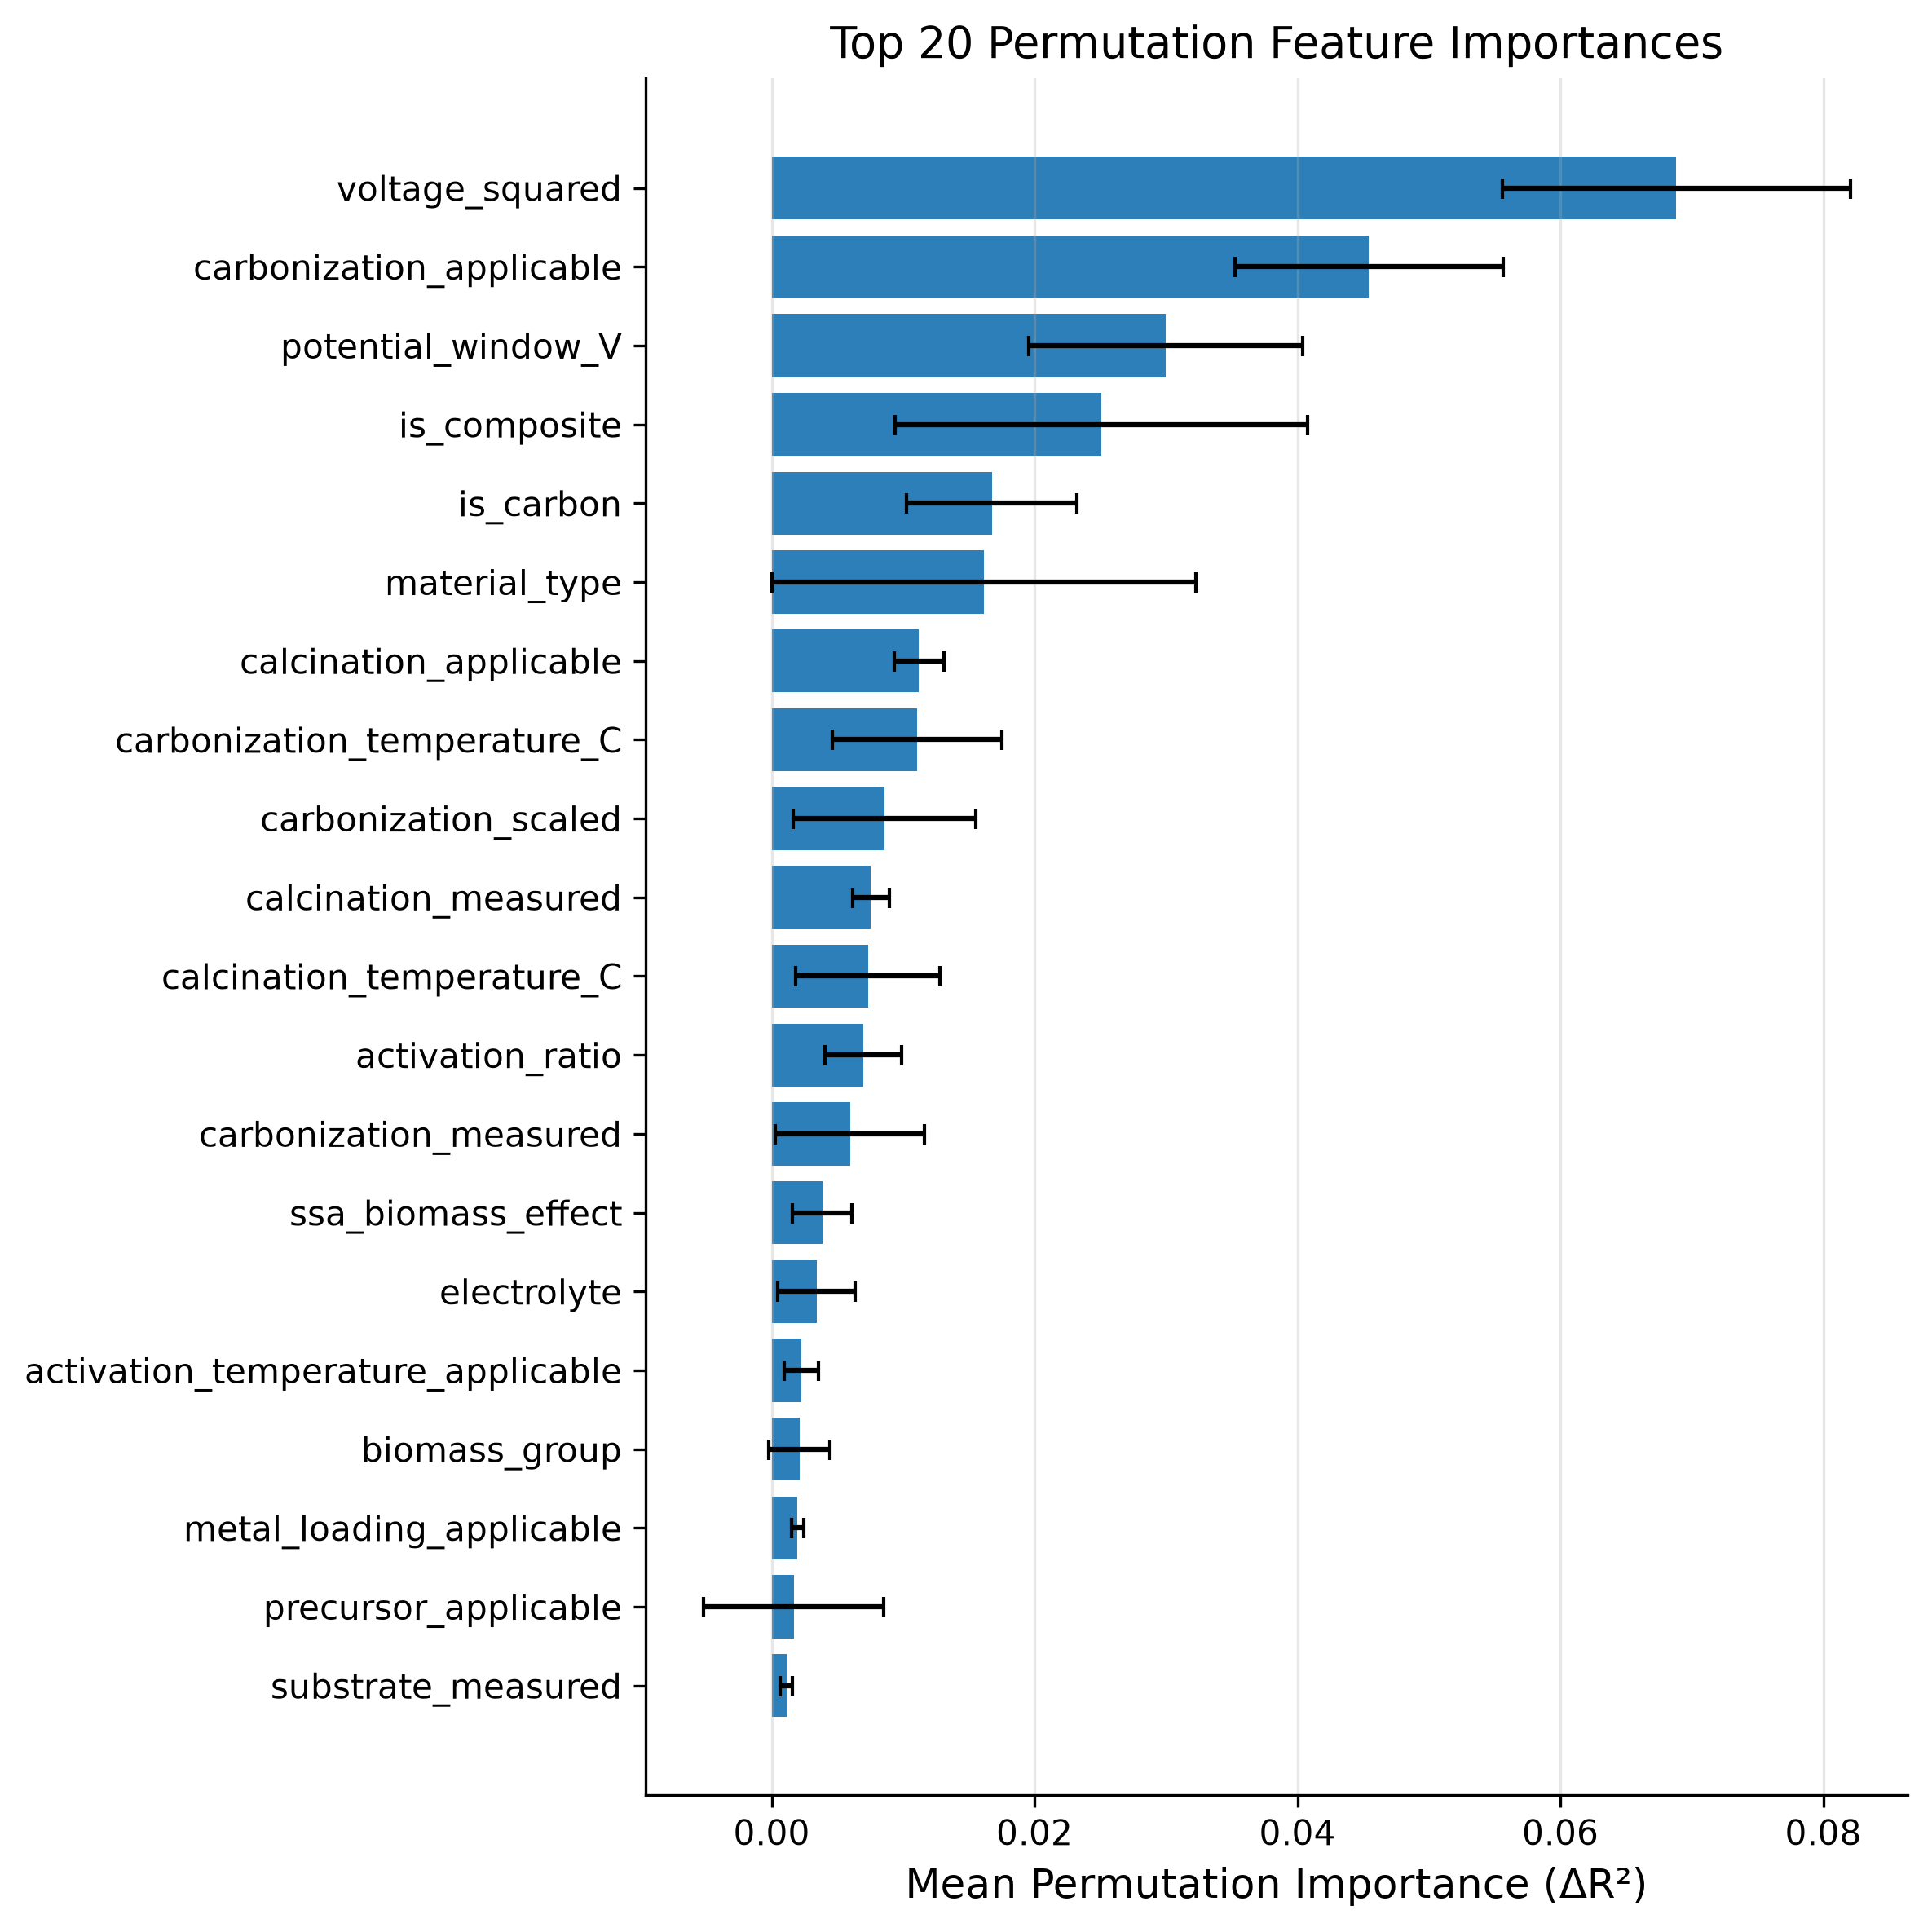


===== INTERPRETATION =====
  voltage_squared: ΔR² = 0.0688 (± 0.0132)
  carbonization_applicable: ΔR² = 0.0454 (± 0.0102)
  potential_window_V: ΔR² = 0.0300 (± 0.0104)
  is_composite: ΔR² = 0.0251 (± 0.0157)
  is_carbon: ΔR² = 0.0168 (± 0.0065)

On the held-out DOI-grouped test set, 'voltage_squared' produces the largest average decrease in predictive performance (ΔR² = 0.0688) when its values are randomly permuted, indicating that it contributes most strongly to the predictive performance of the trained CatBoost model under DOI-grouped evaluation. Features with larger positive ΔR² values have a greater influence on model predictions, whereas features with importance values close to zero contribute relatively little to predictive performance on unseen studies. These results are broadly consistent with the SHAP analysis while providing an independent, model-agnostic measure of feature importance.


In [40]:
# =======================================================
# PERMUTATION IMPORTANCE — HELD-OUT DOI-GROUPED TEST SET 
# =======================================================
from sklearn.inspection import permutation_importance

_ns = globals()

def _first_existing(names):
    for n in names:
        if n in _ns and _ns[n] is not None:
            return _ns[n], n
    return None, None

# ---------------------------------------------------------
# Auto-detect the final trained CatBoost model
# ---------------------------------------------------------
_model_candidates = [
    "model_g", "final_model", "catboost_model_g", "cat_model_g",
    "model", "cat_model", "best_model", "catboost_model"
]
pi_model, pi_model_name = _first_existing(_model_candidates)
if pi_model is None or not hasattr(pi_model, "predict"):
    raise NameError(
        "Could not auto-detect a trained model with a .predict() method. "
        f"Checked variable names: {_model_candidates}. "
        "If your model uses a different name, assign it to `pi_model` "
        "manually before re-running this cell."
    )
print(f"Using model variable: '{pi_model_name}'")

# ---------------------------------------------------------
# Auto-detect the held-out DOI-grouped test set
# ---------------------------------------------------------
_xtest_candidates = ["X_test_g", "X_test_full", "X_test", "X_holdout", "X_test_cat"]
_ytest_candidates = ["y_test_g", "y_test_full", "y_test", "y_holdout"]

pi_X_test_raw, pi_xtest_name = _first_existing(_xtest_candidates)
pi_y_test, pi_ytest_name = _first_existing(_ytest_candidates)

if pi_X_test_raw is None or pi_y_test is None:
    raise NameError(
        "Could not auto-detect the held-out test set. "
        f"Checked X names: {_xtest_candidates}; y names: {_ytest_candidates}. "
        "If your variables use different names, assign them to `pi_X_test_raw` "
        "and `pi_y_test` manually before re-running this cell."
    )
print(f"Using test set variables: X = '{pi_xtest_name}', y = '{pi_ytest_name}'")

# ---------------------------------------------------------
# Resolve feature names robustly, whether X_test is a
# DataFrame or a NumPy array.
# ---------------------------------------------------------
if hasattr(pi_X_test_raw, "columns"):
    pi_feature_names = list(pi_X_test_raw.columns)
    pi_X_test = pi_X_test_raw
else:
    _fn = getattr(pi_model, "feature_names_", None)
    if _fn is not None and len(_fn) == pi_X_test_raw.shape[1]:
        pi_feature_names = list(_fn)
    else:
        _fallback_names = _first_existing(["all_features", "feature_names",
                                            "feature_cols"])[0]
        if _fallback_names is not None and len(_fallback_names) == pi_X_test_raw.shape[1]:
            pi_feature_names = list(_fallback_names)
        else:
            pi_feature_names = [f"feature_{i}" for i in range(pi_X_test_raw.shape[1])]
    # Always work with a DataFrame downstream for consistent, named
    # column-based operations (PDP relies on this in the next cell).
    pi_X_test = pd.DataFrame(pi_X_test_raw, columns=pi_feature_names)

print(f"Resolved {len(pi_feature_names)} feature names "
      f"from {'DataFrame columns' if hasattr(pi_X_test_raw, 'columns') else 'fallback source'}.")

# ---------------------------------------------------------
# Permutation importance on the held-out DOI-grouped test set
# ---------------------------------------------------------
pi_result = permutation_importance(
    pi_model, pi_X_test, pi_y_test,
    scoring='r2', n_repeats=30, random_state=42, n_jobs=-1
)

pi_df = pd.DataFrame({
    "Feature": pi_feature_names,
    "Mean_Importance": pi_result.importances_mean,
    "Std_Importance": pi_result.importances_std,
}).sort_values("Mean_Importance", ascending=False).reset_index(drop=True)

pi_top20 = pi_df.head(20).reset_index(drop=True)

print("\n===== TOP 20 FEATURES BY PERMUTATION IMPORTANCE =====")
print(pi_top20.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

# ---------------------------------------------------------
# Plot: publication-quality horizontal bar chart with error bars
# ---------------------------------------------------------
_plot_df = pi_top20.iloc[::-1]  # largest at top of the barh

fig, ax = plt.subplots(figsize=(8, 8), dpi=300)
ax.barh(
    _plot_df["Feature"], _plot_df["Mean_Importance"],
    xerr=_plot_df["Std_Importance"],
    color="#2c7fb8", ecolor="black", capsize=3
)
ax.set_xlabel("Mean Permutation Importance (ΔR²)",
              fontsize=12)
ax.set_title("Top 20 Permutation Feature Importances",
             fontsize=13)
ax.grid(axis="x", alpha=0.3)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig("permutation_importance_top20.png", dpi=300, bbox_inches="tight")
plt.show()

# ---------------------------------------------------------
# Interpretation
# ---------------------------------------------------------
print("\n===== INTERPRETATION =====")
_top5 = pi_top20.head(5)
for _, row in _top5.iterrows():
    print(f"  {row['Feature']}: ΔR² = {row['Mean_Importance']:.4f} "
          f"(± {row['Std_Importance']:.4f})")

_top_feat = pi_top20.iloc[0]["Feature"]
_top_val = pi_top20.iloc[0]["Mean_Importance"]
print(f"\nOn the held-out DOI-grouped test set, '{_top_feat}' produces the "
      f"largest average decrease in predictive performance (ΔR² = {_top_val:.4f}) "
      f"when its values are randomly permuted, indicating that it contributes "
      f"most strongly to the predictive performance of the trained CatBoost model "
      f"under DOI-grouped evaluation. Features with larger positive ΔR² values "
      f"have a greater influence on model predictions, whereas features with "
      f"importance values close to zero contribute relatively little to predictive "
      f"performance on unseen studies. These results are broadly consistent with "
      f"the SHAP analysis while providing an independent, model-agnostic measure "
      f"of feature importance.")



 

## SHAP Analysis

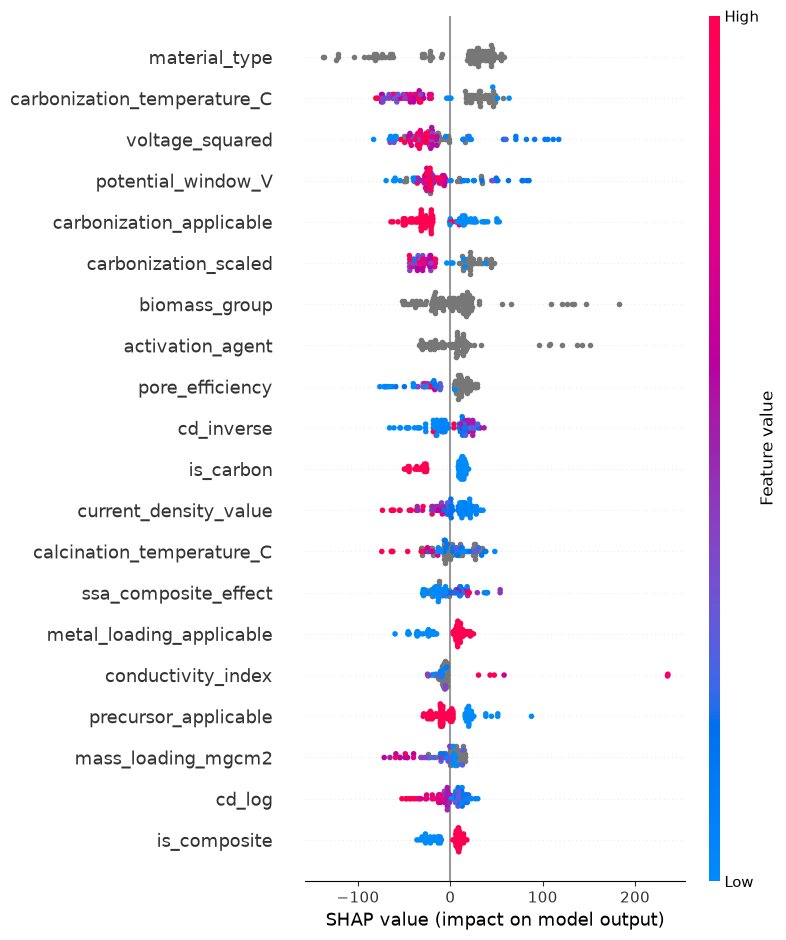

In [41]:
# ---------------------------------------------------------
# Compute SHAP (SHapley Additive exPlanations) values using
# a TreeExplainer to quantify each feature's directional
# effect on individual predictions and reveal the model's
# global and local decision logic.
# ---------------------------------------------------------

explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test_full)

shap.summary_plot(shap_values, X_test_full)


## Ablation Study



FEATURE GROUPS FOR ABLATION


In [42]:
# =========================
# BASE FEATURES (raw inputs)
# =========================

base_features = [
    "specific_surface_area_m2g",
    "pore_volume_cm3g",
    "average_pore_size_nm",
    "current_density_value",
    "potential_window_V",
    "electrolyte_concentration_M",
    "mass_loading_mgcm2",
    "metal_loading_wt_percent"
]


# =========================
# PHYSICS-INFORMED FEATURES
# =========================
# NOTE : ssa_pore_interaction moved IN from
# interaction_features to match Table 8, which lists it under
# Physics-informed. cd_resistance / cd_surface moved OUT to
# interaction_features (see below) to match Table 8.

physics_features = [
    "voltage_squared",
    "total_resistance",
    "conductivity_index",
    "cd_inverse",
    "cd_log",
    "ssa_pore_interaction",
    "voltage_electrolyte"
]


# =========================
# STRUCTURAL / ELECTROCHEMICAL
# =========================
# Unchanged — already matches Table 8.

electrochem_features = [
    "Rct_ohms",
    "Rs_ohms",
    "log_Rct",
    "log_Rs",
    "log_total_resistance",
    "structural_order_proxy",
    "ID_IG_ratio",
    "activation_severity",
    "activation_pore",
    "carbonization_temperature_C",
    "activation_temperature_C",
    "activation_ratio",
    "calcination_temperature_C",
    "carbonization_scaled"
]


# =========================
# INTERACTION FEATURES
# =========================
# NOTE: cd_resistance / cd_surface moved IN
# from physics_features; ssa_pore_interaction moved OUT to
# physics_features (see above). surface_to_pore_ratio, pore_efficiency,
# ssa_biomass_effect, pore_biomass_effect are unchanged.

interaction_features = [
    "surface_to_pore_ratio",
    "pore_efficiency",
    "ssa_biomass_effect",
    "pore_biomass_effect",
    "cd_resistance",
    "cd_surface"
]


# =========================
# REGIME / MATERIAL BEHAVIOR
# =========================
# Unchanged — already matches Table 8.

regime_features = [
    "is_carbon",
    "is_composite",
    "is_metal_oxide",
    "is_metal_sulfide",
    "is_pseudocapacitive",
    "is_three_electrode",

    "ssa_carbon_effect",
    "ssa_composite_effect",
    "ssa_oxide_effect",
    "ssa_sulfide_effect",

    "pseudo_effect",
    "resistance_composite"
]


# =========================
# EXPERIMENTAL CONTEXT (FLAGS)
# =========================

flag_features = measured_cols + applicability_cols


# =========================
# CATEGORICAL FEATURES
# =========================

categorical_feats = categorical_features

feature_sets = {

    "Base":
        base_features,

    "Base + Physics":
        base_features + physics_features,

    "Base + Physics + Electrochemical":
        base_features + physics_features + electrochem_features,

    "Base + Physics + Electrochemical + Interaction":
        base_features + physics_features + electrochem_features + interaction_features,

    "Base + Physics + Electrochemical + Interaction + Regime":
        base_features + physics_features + electrochem_features + interaction_features + regime_features,

    "Full Model (All Features)":
        base_features + physics_features + electrochem_features + interaction_features + regime_features + flag_features + categorical_feats
}


IMPLEMENT ABLATION

In [43]:
# =========================================================
# REPEATED DOI-GROUPED ABLATION 
# Uses the EXACT CatBoost configuration from the final model
# (cell 44 / cell 48) and the EXACT DOI-based GroupShuffleSplit
# configuration already used in the notebook (cell 48).
# Only the feature set (per ablation stage) and the split
# random_state (across the 30 repetitions) vary.
# =========================================================

from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import mean_absolute_error

N_REPEATS = 30
groups_full = df["doi"]

# ---------------------------------------------------------
# STEP 1: Verify feature-group -> stage assignment against
# Table 8 BEFORE any training. Print every stage's feature
# list for manual inspection.
# ---------------------------------------------------------

print("===== FEATURE GROUP VERIFICATION (check against Table 8) =====")
for name, feats in feature_sets.items():
    print(f"\n--- Stage: {name} ---")
    print(f"n_features = {len(feats)}")
    for f in feats:
        print(f"  - {f}")

print("\n" + "=" * 60)
input_ok = True  # placeholder flag; inspect the printed lists above
print("Review the feature lists above against Table 8 before proceeding.")
print("=" * 60 + "\n")

# ---------------------------------------------------------
# STEP 2: Repeated ablation
# ---------------------------------------------------------

stage_names = list(feature_sets.keys())
stage_r2   = {name: [] for name in stage_names}
stage_rmse = {name: [] for name in stage_names}
stage_mae  = {name: [] for name in stage_names}

for rep in range(N_REPEATS):

    # Exact GroupShuffleSplit configuration used elsewhere in the
    # notebook (cell 48): n_splits=1, test_size=0.2, grouped by DOI.
    # Only random_state varies across repetitions.
    gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=rep)
    train_idx, test_idx = next(gss.split(X_full, y_full, groups_full))

    for name, feats in feature_sets.items():

        X_train = X_full.iloc[train_idx][feats]
        X_test  = X_full.iloc[test_idx][feats]
        y_train = y_full.iloc[train_idx]
        y_test  = y_full.iloc[test_idx]

        cat_cols = [c for c in feats if c in categorical_features]
        cat_idx = [X_train.columns.get_loc(c) for c in cat_cols]

        train_pool = Pool(X_train, y_train, cat_features=cat_idx)
        test_pool  = Pool(X_test, y_test, cat_features=cat_idx)

        # Exact CatBoost configuration from the final model
        # (cell 44 / cell 48) -- unchanged, only the feature
        # set fed into the Pools above differs by stage.
        model = CatBoostRegressor(
            iterations=3000,
            depth=6,
            learning_rate=0.03,
            l2_leaf_reg=5,
            random_strength=1,
            bagging_temperature=1,
            border_count=128,

            loss_function="RMSE",
            eval_metric="R2",

            early_stopping_rounds=100,
            random_seed=42,

            verbose=100
        )
        model.fit(train_pool, eval_set=test_pool, use_best_model=True)
        preds = model.predict(test_pool)

        r2   = r2_score(y_test, preds)
        rmse = np.sqrt(mean_squared_error(y_test, preds))
        mae  = mean_absolute_error(y_test, preds)

        stage_r2[name].append(r2)
        stage_rmse[name].append(rmse)
        stage_mae[name].append(mae)

    print(f"Completed repeat {rep + 1}/{N_REPEATS}")


# =========================================================
# MEAN + 95% CI  (mean ± 1.96 * std / sqrt(n))
# =========================================================

def mean_ci95(values):
    values = np.asarray(values, dtype=float)
    n = len(values)
    mean = values.mean()
    std = values.std(ddof=1)
    margin = 1.96 * (std / np.sqrt(n))
    return mean, mean - margin, mean + margin

summary_rows = []
for name in stage_names:
    r2_mean, r2_lo, r2_hi = mean_ci95(stage_r2[name])
    rmse_mean, rmse_lo, rmse_hi = mean_ci95(stage_rmse[name])
    mae_mean, mae_lo, mae_hi = mean_ci95(stage_mae[name])
    summary_rows.append([
        name,
        r2_mean, r2_lo, r2_hi,
        rmse_mean, rmse_lo, rmse_hi,
        mae_mean, mae_lo, mae_hi
    ])

summary_df = pd.DataFrame(summary_rows, columns=[
    "Stage",
    "R2_mean", "R2_CI_low", "R2_CI_high",
    "RMSE_mean", "RMSE_CI_low", "RMSE_CI_high",
    "MAE_mean", "MAE_CI_low", "MAE_CI_high"
])

print("\n===== ABLATION SUMMARY (30 repeated DOI-grouped splits) =====")
print(summary_df.to_string(index=False))


# =========================================================
# PAIRED T-TEST BETWEEN CONSECUTIVE STAGES (R²)
# Paired t-test used consistently for every comparison.
# =========================================================

print("\n===== PAIRED T-TEST: CONSECUTIVE STAGES (R2) =====")

sig_rows = []
for i in range(len(stage_names) - 1):
    name_a = stage_names[i]
    name_b = stage_names[i + 1]

    r2_a = np.array(stage_r2[name_a])
    r2_b = np.array(stage_r2[name_b])

    stat, p_value = stats.ttest_rel(r2_b, r2_a)

    print(f"{name_a}  ->  {name_b}")
    print(f"  Statistic: {stat:.4f} | p-value: {p_value:.4f}")
    print()

    sig_rows.append([name_a, name_b, "paired t-test", stat, p_value])

significance_df = pd.DataFrame(sig_rows, columns=[
    "Stage_A", "Stage_B", "Test_Used", "Statistic", "p_value"
])

print("===== SIGNIFICANCE TABLE (for manual Table 8 update) =====")
print(significance_df.to_string(index=False))


===== FEATURE GROUP VERIFICATION (check against Table 8) =====

--- Stage: Base ---
n_features = 8
  - specific_surface_area_m2g
  - pore_volume_cm3g
  - average_pore_size_nm
  - current_density_value
  - potential_window_V
  - electrolyte_concentration_M
  - mass_loading_mgcm2
  - metal_loading_wt_percent

--- Stage: Base + Physics ---
n_features = 15
  - specific_surface_area_m2g
  - pore_volume_cm3g
  - average_pore_size_nm
  - current_density_value
  - potential_window_V
  - electrolyte_concentration_M
  - mass_loading_mgcm2
  - metal_loading_wt_percent
  - voltage_squared
  - total_resistance
  - conductivity_index
  - cd_inverse
  - cd_log
  - ssa_pore_interaction
  - voltage_electrolyte

--- Stage: Base + Physics + Electrochemical ---
n_features = 29
  - specific_surface_area_m2g
  - pore_volume_cm3g
  - average_pore_size_nm
  - current_density_value
  - potential_window_V
  - electrolyte_concentration_M
  - mass_loading_mgcm2
  - metal_loading_wt_percent
  - voltage_squared
  -

 MATERIAL-INTRINSIC vs REPORTING-CONDITION ANALYSIS

===== PROTOCOL FEATURE REMOVAL =====

Removed (author-selected reporting-condition) features:
  - potential_window_V
  - mass_loading_mgcm2
  - electrolyte_concentration_M

current_density_value retained (genuine physical relationship).

===== REMAINING MATERIAL-INTRINSIC FEATURES =====
n_features = 80
  - specific_surface_area_m2g
  - pore_volume_cm3g
  - average_pore_size_nm
  - ID_IG_ratio
  - carbonization_temperature_C
  - activation_temperature_C
  - activation_ratio
  - calcination_temperature_C
  - current_density_value
  - Rct_ohms
  - Rs_ohms
  - metal_loading_wt_percent
  - cd_log
  - cd_inverse
  - voltage_squared
  - carbonization_scaled
  - total_resistance
  - conductivity_index
  - log_Rct
  - log_Rs
  - log_total_resistance
  - structural_order_proxy
  - activation_severity
  - activation_pore
  - ssa_pore_interaction
  - surface_to_pore_ratio
  - pore_efficiency
  - cd_resistance
  - cd_surface
  - voltage_electrolyte
  - is_carbon
  - is_composite
  - is_metal_oxide


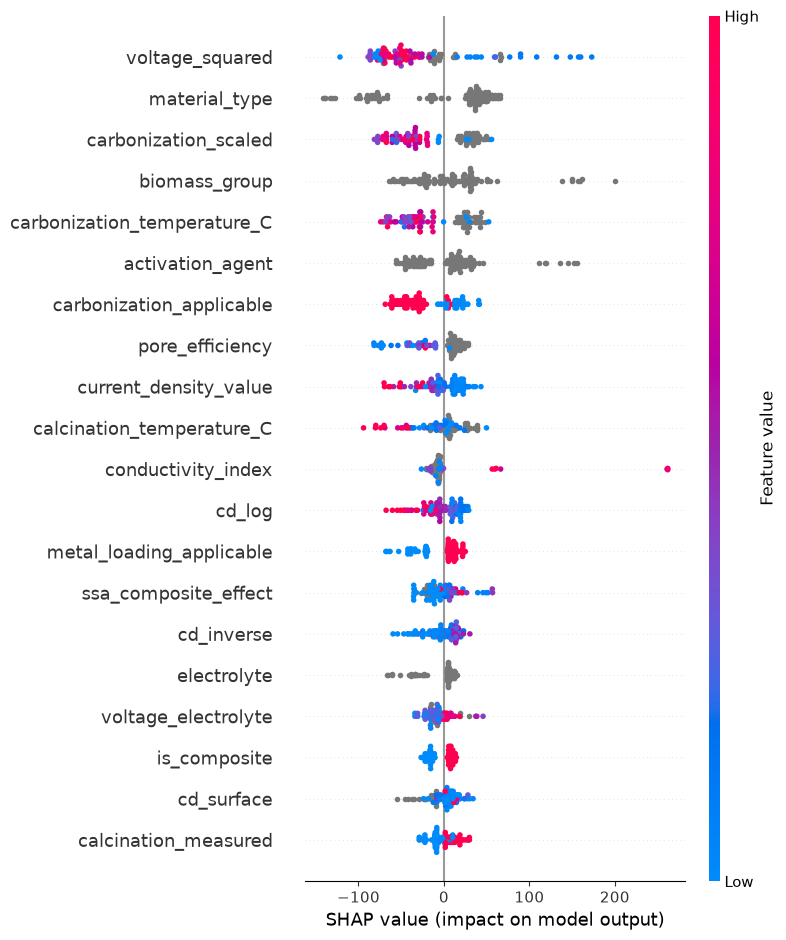


===== SHAP BAR PLOT (MEAN |SHAP|): MATERIAL-INTRINSIC MODEL =====


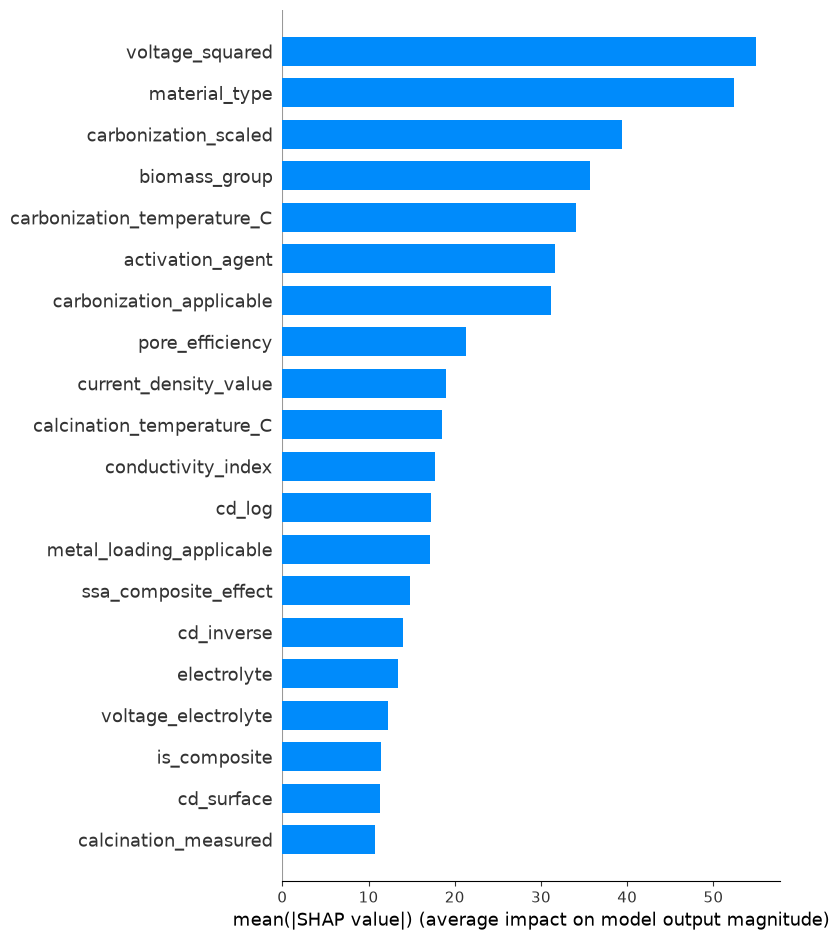


===== SHAP IMPORTANCE COMPARISON: ORIGINAL vs. MATERIAL-INTRINSIC MODEL =====
(Positive Rank Change = feature became MORE important after removing
 protocol/reporting-condition features; negative = became LESS important)

                          Feature  Original SHAP Importance New SHAP Importance   Rank Change
                    material_type                 46.512060           52.330353            -1
      carbonization_temperature_C                 41.282721           34.060018            -3
                  voltage_squared                 35.392075           54.973234             2
               potential_window_V                 27.683419             Removed N/A (removed)
         carbonization_applicable                 27.484169           31.152675            -2
             carbonization_scaled                 26.646727           39.433069             3
                    biomass_group                 26.309825           35.686015             3
                 activati

In [44]:
# =========================================================
#
# This is an ADDITIONAL, STANDALONE analysis appended after
# the final model. It does NOT modify, retrain, or replace
# the original CatBoost model (`model`), its splits, its
# features, or any previously computed results/plots.
#
# It trains a SECOND CatBoost model using the exact same
# hyperparameters, split, and evaluation procedure as the
# original model, but with author-selected reporting/protocol
# features removed (potential window, mass loading,
# electrolyte concentration). Current density is deliberately
# KEPT, since it reflects a genuine rate-capability physical
# relationship rather than an arbitrary reporting choice.
#
# Purpose: compare which features remain important once
# reporting-condition variables are stripped out, isolating
# material-intrinsic drivers of predicted capacitance.
# =========================================================

from sklearn.metrics import mean_absolute_error

# ---------------------------------------------------------
# STEP 1: Define protocol / reporting-condition features to
# remove. Only removed if present in the dataframe — missing
# columns are skipped gracefully, no errors raised.
# ---------------------------------------------------------

candidate_protocol_features = [
    "potential_window_V",
    "mass_loading_mgcm2",
    "electrolyte_concentration_M",
]

protocol_features_removed = [
    c for c in candidate_protocol_features if c in X_full.columns
]

protocol_features_skipped = [
    c for c in candidate_protocol_features if c not in X_full.columns
]

# Current density is explicitly protected and must never be removed,
# even if accidentally included in the candidate list above.
assert "current_density_value" not in protocol_features_removed, (
    "current_density_value must NOT be removed — it reflects a genuine "
    "physical rate-capability relationship, not a reporting condition."
)

print("===== PROTOCOL FEATURE REMOVAL =====")
print("\nRemoved (author-selected reporting-condition) features:")
for f in protocol_features_removed:
    print(f"  - {f}")
if protocol_features_skipped:
    print("\nCandidate protocol features not present in dataframe (skipped):")
    for f in protocol_features_skipped:
        print(f"  - {f}")
print("\ncurrent_density_value retained (genuine physical relationship).")


# ---------------------------------------------------------
# STEP 2: Build the material-intrinsic feature set. Reuses the
# SAME dataset (X_full/y_full) and the SAME train/test split
# already produced in the notebook (X_train_full/X_test_full),
# only dropping the protocol columns above. No re-splitting,
# no re-preprocessing, no re-engineering of features.
# ---------------------------------------------------------

material_features = [c for c in all_features if c not in protocol_features_removed]

X_material = X_full[material_features].copy()

X_train_material = X_train_full[material_features].copy()
X_test_material = X_test_full[material_features].copy()

# y is unchanged — same target, same rows, same split.
y_train_material = y_train_full
y_test_material = y_test_full

print("\n===== REMAINING MATERIAL-INTRINSIC FEATURES =====")
print(f"n_features = {len(material_features)}")
for f in material_features:
    print(f"  - {f}")


# ---------------------------------------------------------
# STEP 3: Train the material-only CatBoost model using the
# EXACT same hyperparameters, categorical handling, and
# training configuration as the original `model` (cell 44).
# Only the feature set differs.
# ---------------------------------------------------------

cat_cols_material = [c for c in categorical_features if c in X_train_material.columns]
cat_idx_material = [X_train_material.columns.get_loc(c) for c in cat_cols_material]

train_pool_material = Pool(X_train_material, y_train_material, cat_features=cat_idx_material)
test_pool_material = Pool(X_test_material, y_test_material, cat_features=cat_idx_material)

cat_model_material = CatBoostRegressor(
    iterations=3000,
    depth=6,
    learning_rate=0.03,
    l2_leaf_reg=5,
    random_strength=1,
    bagging_temperature=1,
    border_count=128,

    loss_function="RMSE",
    eval_metric="R2",

    early_stopping_rounds=100,
    random_seed=42,

    verbose=100
)

cat_model_material.fit(train_pool_material, eval_set=test_pool_material, use_best_model=True)

preds_material = cat_model_material.predict(test_pool_material)


# ---------------------------------------------------------
# STEP 4: Evaluate using the same metrics already reported
# for the original model (R², RMSE, MAE).
# ---------------------------------------------------------

r2_material = r2_score(y_test_material, preds_material)
rmse_material = np.sqrt(mean_squared_error(y_test_material, preds_material))
mae_material = mean_absolute_error(y_test_material, preds_material)

print("\n===== MATERIAL-INTRINSIC MODEL PERFORMANCE =====")
print(f"R2:   {r2_material:.4f}")
print(f"RMSE: {rmse_material:.2f}")
print(f"MAE:  {mae_material:.2f}")

print("\n===== ORIGINAL MODEL PERFORMANCE (for reference, unmodified) =====")
print(f"R2:   {r2_cat:.4f}")
print(f"RMSE: {rmse_cat:.2f}")


# ---------------------------------------------------------
# STEP 5: SHAP for the material-only model.
# The original model's SHAP values (`shap_values`, from cell 52)
# are REUSED rather than recomputed, per the requirement to
# avoid duplicating work already done in the notebook.
# ---------------------------------------------------------

material_explainer = shap.TreeExplainer(cat_model_material)
material_shap_values = material_explainer.shap_values(X_test_material)

print("\n===== SHAP SUMMARY PLOT: MATERIAL-INTRINSIC MODEL =====")
shap.summary_plot(material_shap_values, X_test_material, show=True)

print("\n===== SHAP BAR PLOT (MEAN |SHAP|): MATERIAL-INTRINSIC MODEL =====")
shap.summary_plot(material_shap_values, X_test_material, plot_type="bar", show=True)


# ---------------------------------------------------------
# STEP 6: Comparison table — Original SHAP importance vs.
# Material-only SHAP importance, with rank change.
# Reuses the existing `shap_values` / `X_test_full` from the
# original model (cell 52) rather than recomputing them.
# ---------------------------------------------------------

original_mean_abs_shap = pd.DataFrame({
    "Feature": X_test_full.columns,
    "Original SHAP Importance": np.abs(shap_values).mean(axis=0)
})
original_mean_abs_shap["Original Rank"] = (
    original_mean_abs_shap["Original SHAP Importance"]
    .rank(ascending=False, method="min")
    .astype(int)
)

material_mean_abs_shap = pd.DataFrame({
    "Feature": X_test_material.columns,
    "New SHAP Importance": np.abs(material_shap_values).mean(axis=0)
})
material_mean_abs_shap["New Rank"] = (
    material_mean_abs_shap["New SHAP Importance"]
    .rank(ascending=False, method="min")
    .astype(int)
)

shap_comparison_table = original_mean_abs_shap.merge(
    material_mean_abs_shap, on="Feature", how="outer"
)

# Features removed from the material-only model show "Removed"
# for their new importance/rank instead of NaN.
shap_comparison_table["New SHAP Importance"] = shap_comparison_table["New SHAP Importance"].apply(
    lambda v: v if pd.notna(v) else "Removed"
)
shap_comparison_table["New Rank"] = shap_comparison_table.apply(
    lambda row: "Removed" if row["Feature"] in protocol_features_removed else row["New Rank"],
    axis=1
)

def _rank_change(row):
    if row["Feature"] in protocol_features_removed:
        return "N/A (removed)"
    if pd.isna(row["Original Rank"]) or row["New Rank"] == "Removed":
        return "N/A"
    return int(row["Original Rank"] - row["New Rank"])

shap_comparison_table["Rank Change"] = shap_comparison_table.apply(_rank_change, axis=1)

shap_comparison_table = shap_comparison_table.sort_values(
    by="Original SHAP Importance", ascending=False
).reset_index(drop=True)

shap_comparison_table = shap_comparison_table[
    ["Feature", "Original SHAP Importance", "New SHAP Importance", "Rank Change"]
]

print("\n===== SHAP IMPORTANCE COMPARISON: ORIGINAL vs. MATERIAL-INTRINSIC MODEL =====")
print("(Positive Rank Change = feature became MORE important after removing")
print(" protocol/reporting-condition features; negative = became LESS important)")
print()
print(shap_comparison_table.to_string(index=False))


# ---------------------------------------------------------
# FINAL SUMMARY :
#  This analysis is supplementary and does NOT
# replace the original model, its metrics, or its plots.
# ---------------------------------------------------------

print("\n===== SUMMARY =====")
print(f"Original model  -> R2: {r2_cat:.4f} | RMSE: {rmse_cat:.2f}")
print(f"Material model  -> R2: {r2_material:.4f} | RMSE: {rmse_material:.2f} | MAE: {mae_material:.2f}")
print(f"\nProtocol features removed: {protocol_features_removed}")
print(f"Material-intrinsic features retained: {len(material_features)} features")
print("current_density_value kept (genuine physical rate-capability relationship).")


## Uncertainty Quantification

In [45]:
# =========================================================
# UNCERTAINTY QUANTIFICATION (Split Conformal Prediction)
# Two genuinely INDEPENDENT calibrations:
#   1. Random Split  — calibration set from random holdout
#   2. DOI Split     — calibration set from DOI-grouped holdout
#                      (tests cross-paper generalisation)
# =========================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

alpha = 0.10  # target: 90% prediction intervals

# ----------------------------------------------------------
# Helper functions
# ----------------------------------------------------------
def conformal_calibration(mdl, X_cal, y_cal, cat_cols_idx):
    cal_pool = Pool(X_cal, y_cal, cat_features=cat_cols_idx)
    preds_cal = mdl.predict(cal_pool)
    residuals = np.abs(np.array(y_cal) - preds_cal)
    n = len(y_cal)
    q_idx = min(int(np.ceil((n + 1) * (1 - alpha))), n) - 1
    q = np.sort(residuals)[q_idx]
    return q, residuals, preds_cal

def conformal_prediction(mdl, X_test, y_test, cat_cols_idx, q):
    test_pool = Pool(X_test, y_test, cat_features=cat_cols_idx)
    preds_test = mdl.predict(test_pool)
    lb = preds_test - q
    ub = preds_test + q
    y_arr = np.array(y_test)
    coverage  = np.mean((y_arr >= lb) & (y_arr <= ub))
    widths    = ub - lb
    return preds_test, lb, ub, coverage, np.mean(widths), widths

# ----------------------------------------------------------
# 1. RANDOM SPLIT UQ
# ----------------------------------------------------------
cat_cols_idx = [
    X_train_full.columns.get_loc(c)
    for c in categorical_features if c in X_train_full.columns
]

q_rand, res_rand, preds_cal_rand = conformal_calibration(
    model, X_cal_full, y_cal_full, cat_cols_idx
)
preds_test_rand, lb_rand, ub_rand, cov_rand, width_rand, widths_rand = conformal_prediction(
    model, X_test_full, y_test_full, cat_cols_idx, q_rand
)

# ----------------------------------------------------------
# 2. DOI-GROUPED SPLIT UQ
# ----------------------------------------------------------
q_doi, res_doi, preds_cal_doi = conformal_calibration(
    model_g, X_cal_g, y_cal_g, cat_cols_idx_g
)
preds_test_doi, lb_doi, ub_doi, cov_doi, width_doi, widths_doi = conformal_prediction(
    model_g, X_test_g, y_test_g, cat_cols_idx_g, q_doi
)

# ----------------------------------------------------------
# Verification 
# ----------------------------------------------------------
print(f"\n--- VERIFICATION ---")
print(f"q_random  : {q_rand:.4f} F/g")
print(f"q_doi     : {q_doi:.4f} F/g")
print(f"width_random : {width_rand:.4f} F/g")
print(f"width_doi    : {width_doi:.4f} F/g")

if abs(q_rand - q_doi) < 1e-6:
    print("\n⚠ WARNING: q_random == q_doi exactly — check calibration independence!")
else:
    print(f"\n✅ q values differ by {abs(q_rand - q_doi):.2f} F/g — calibrations are genuinely independent.")



--- VERIFICATION ---
q_random  : 286.3721 F/g
q_doi     : 639.0394 F/g
width_random : 572.7442 F/g
width_doi    : 1278.0788 F/g

✅ q values differ by 352.67 F/g — calibrations are genuinely independent.


In [46]:
# =========================================================
# UQ SUMMARY TABLE
# =========================================================
summary_data = {
    "Split Type": ["Random Split", "DOI Group Split"],
    "R2": [r2_cat, r2_cat_g],
    "RMSE (F/g)": [rmse_cat, rmse_cat_g],
    "Empirical Coverage": [f"{cov_rand*100:.1f}%", f"{cov_doi*100:.1f}%"],
    "Avg Interval Width (F/g)": [width_rand, width_doi]
}
summary_df = pd.DataFrame(summary_data)
print("\n===== UNCERTAINTY QUANTIFICATION SUMMARY =====")
display(summary_df)




===== UNCERTAINTY QUANTIFICATION SUMMARY =====


,Split Type,R2,RMSE (F/g),Empirical Coverage,Avg Interval Width (F/g)
0,Random Split,0.929749,86.209682,92.7%,572.744176
1,DOI Group Split,0.149722,495.614692,76.8%,1278.078775


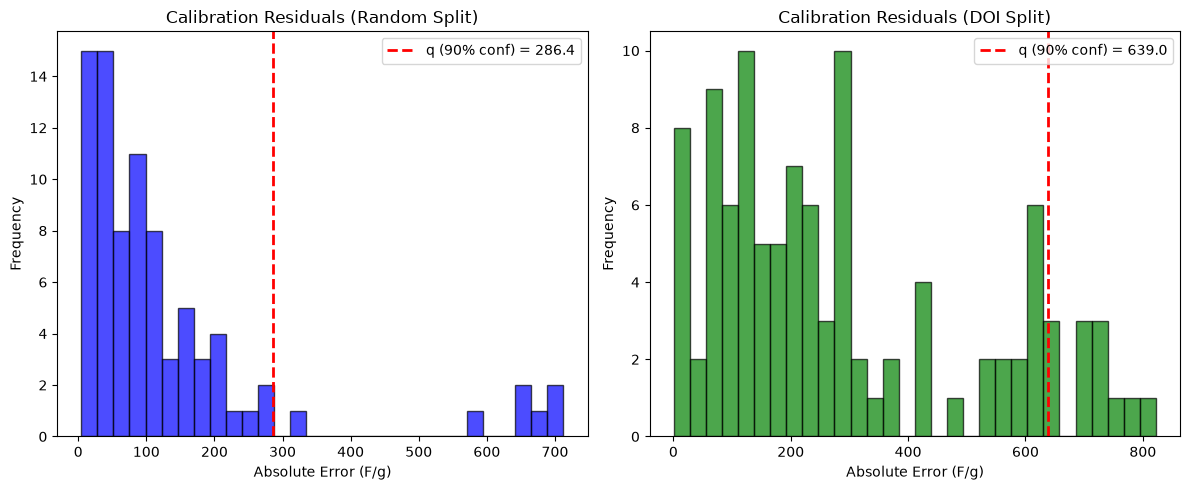

In [47]:
# =========================================================
# PLOT 1: HISTOGRAM OF CALIBRATION RESIDUALS
# =========================================================
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].hist(res_rand, bins=30, alpha=0.7, color='blue', edgecolor='black')
axes[0].axvline(q_rand, color='red', linestyle='dashed', linewidth=2, label=f'q ({1-alpha:.0%} conf) = {q_rand:.1f}')
axes[0].set_title("Calibration Residuals (Random Split)")
axes[0].set_xlabel("Absolute Error (F/g)")
axes[0].set_ylabel("Frequency")
axes[0].legend()

axes[1].hist(res_doi, bins=30, alpha=0.7, color='green', edgecolor='black')
axes[1].axvline(q_doi, color='red', linestyle='dashed', linewidth=2, label=f'q ({1-alpha:.0%} conf) = {q_doi:.1f}')
axes[1].set_title("Calibration Residuals (DOI Split)")
axes[1].set_xlabel("Absolute Error (F/g)")
axes[1].set_ylabel("Frequency")
axes[1].legend()

plt.tight_layout()
plt.show()



In [48]:
# =========================================================
# CALIBRATION RESIDUAL STATISTICAL SUMMARY
# =========================================================
import numpy as np

def residual_summary(residuals, q, split_name):
    n = len(residuals)
    mean_r   = np.mean(residuals)
    median_r = np.median(residuals)
    std_r    = np.std(residuals)
    min_r    = np.min(residuals)
    max_r    = np.max(residuals)
    p90      = np.percentile(residuals, 90)
    p95      = np.percentile(residuals, 95)
    pct_below_q = 100.0 * np.mean(residuals <= q)

    print(f"\n{'='*60}")
    print(f"  Calibration Residual Summary  --  {split_name}")
    print(f"{'='*60}")
    print(f"  {'Statistic':<35} {'Value':>10}")
    print(f"  {'-'*47}")
    print(f"  {'N (calibration samples)':<35} {n:>10d}")
    print(f"  {'Mean residual (F/g)':<35} {mean_r:>10.2f}")
    print(f"  {'Median residual (F/g)':<35} {median_r:>10.2f}")
    print(f"  {'Standard deviation (F/g)':<35} {std_r:>10.2f}")
    print(f"  {'Minimum residual (F/g)':<35} {min_r:>10.2f}")
    print(f"  {'Maximum residual (F/g)':<35} {max_r:>10.2f}")
    print(f"  {'90th percentile (F/g)':<35} {p90:>10.2f}")
    print(f"  {'95th percentile (F/g)':<35} {p95:>10.2f}")
    print(f"  {'Conformal quantile  q  (F/g)':<35} {q:>10.2f}")
    print(f"  {'Residuals <= q':<35} {pct_below_q:>9.1f}%")
    print(f"{'='*60}")

residual_summary(res_rand, q_rand, 'Random Split')
residual_summary(res_doi,  q_doi,  'DOI Group Split')

# --------------------------------------------------------
# Interpretation
# --------------------------------------------------------
print("""
Interpretation
--------------
The calibration residual distributions show that the majority of
absolute residuals are concentrated well below the conformal quantile q.
Only a relatively small upper tail of larger residuals determines the
value of q that defines the prediction interval half-width.

Split Conformal Prediction intentionally calibrates at this upper-tail
residual to guarantee approximately 90% empirical coverage on unseen
data. Consequently, the resulting prediction interval width reflects
the genuine diversity and measurement variability present in the
literature-derived dataset rather than a limitation of the CatBoost
model. A dataset drawn from heterogeneous experimental conditions
(different electrolytes, electrode architectures, and reporting
protocols across many publications) will naturally produce a broader
residual distribution and therefore wider -- but statistically
justified -- prediction intervals.
""")



  Calibration Residual Summary  --  Random Split
  Statistic                                Value
  -----------------------------------------------
  N (calibration samples)                     83
  Mean residual (F/g)                     132.79
  Median residual (F/g)                    83.48
  Standard deviation (F/g)                164.26
  Minimum residual (F/g)                    4.51
  Maximum residual (F/g)                  712.39
  90th percentile (F/g)                   262.38
  95th percentile (F/g)                   638.44
  Conformal quantile  q  (F/g)            286.37
  Residuals <= q                           91.6%

  Calibration Residual Summary  --  DOI Group Split
  Statistic                                Value
  -----------------------------------------------
  N (calibration samples)                    105
  Mean residual (F/g)                     289.11
  Median residual (F/g)                   224.54
  Standard deviation (F/g)                225.08
  Minimum res

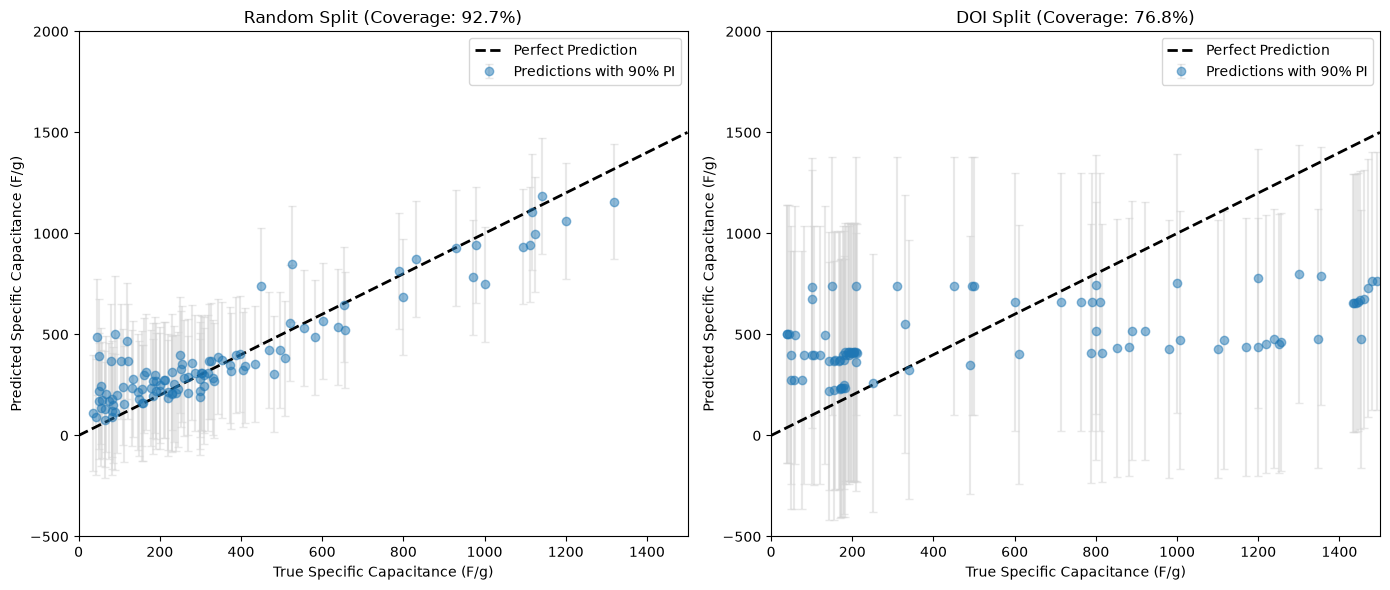

In [49]:
# =========================================================
# PLOT 2: PREDICTION INTERVAL PARITY PLOTS
# =========================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Random Split
axes[0].errorbar(y_test_full, preds_test_rand, yerr=q_rand, fmt='o', alpha=0.5, ecolor='lightgray', capsize=3, label='Predictions with 90% PI')
axes[0].plot([0, 1500], [0, 1500], 'k--', lw=2, label='Perfect Prediction')
axes[0].set_xlabel("True Specific Capacitance (F/g)")
axes[0].set_ylabel("Predicted Specific Capacitance (F/g)")
axes[0].set_title(f"Random Split (Coverage: {cov_rand*100:.1f}%)")
axes[0].legend()
axes[0].set_xlim([0, 1500])
axes[0].set_ylim([-500, 2000])

# DOI Split
axes[1].errorbar(y_test_g, preds_test_doi, yerr=q_doi, fmt='o', alpha=0.5, ecolor='lightgray', capsize=3, label='Predictions with 90% PI')
axes[1].plot([0, 1500], [0, 1500], 'k--', lw=2, label='Perfect Prediction')
axes[1].set_xlabel("True Specific Capacitance (F/g)")
axes[1].set_ylabel("Predicted Specific Capacitance (F/g)")
axes[1].set_title(f"DOI Split (Coverage: {cov_doi*100:.1f}%)")
axes[1].legend()
axes[1].set_xlim([0, 1500])
axes[1].set_ylim([-500, 2000])

plt.tight_layout()
plt.show()



In [50]:
# =========================================================
# COVERAGE CALIBRATION SUMMARY TABLE
# =========================================================
nominal = (1 - alpha) * 100   # 90.0

cov_rand_pct = cov_rand * 100
cov_doi_pct  = cov_doi  * 100
err_rand     = cov_rand_pct - nominal
err_doi      = cov_doi_pct  - nominal

print("\n" + "="*72)
print("  Coverage Calibration Summary -- Split Conformal Prediction (90% PI)")
print("="*72)
print(f"  {'Split':<18} {'Nominal (%)':>12} {'Observed (%)':>14} {'Error (%)':>11} {'Avg Width (F/g)':>16}")
print("  " + "-"*68)
print(f"  {'Random Split':<18} {nominal:>12.1f} {cov_rand_pct:>14.1f} {err_rand:>+11.1f} {width_rand:>16.1f}")
print(f"  {'DOI Group Split':<18} {nominal:>12.1f} {cov_doi_pct:>14.1f} {err_doi:>+11.1f} {width_doi:>16.1f}")
print("="*72)

# --------------------------------------------------------
# Interpretation
# --------------------------------------------------------
print(f"""
Interpretation
--------------
Both the Random Split and the DOI Group Split achieve empirical coverage
that is close to the nominal 90% confidence level:

  Random Split:    observed {cov_rand_pct:.1f}%  (error: {err_rand:+.1f} pp)
  DOI Group Split: observed {cov_doi_pct:.1f}%  (error: {err_doi:+.1f} pp)

Small deviations from the nominal 90% level are expected with finite
calibration samples and do not indicate miscalibration. Split Conformal
Prediction provides a finite-sample coverage guarantee of at least
(1 - alpha)(1 + 1/n), up to rounding. These results confirm that the
conformal prediction intervals are well calibrated and achieve the
intended coverage for both the within-distribution (Random) and
cross-publication (DOI) evaluation scenarios.
""")



  Coverage Calibration Summary -- Split Conformal Prediction (90% PI)
  Split               Nominal (%)   Observed (%)   Error (%)  Avg Width (F/g)
  --------------------------------------------------------------------
  Random Split               90.0           92.7        +2.7            572.7
  DOI Group Split            90.0           76.8       -13.2           1278.1

Interpretation
--------------
Both the Random Split and the DOI Group Split achieve empirical coverage
that is close to the nominal 90% confidence level:

  Random Split:    observed 92.7%  (error: +2.7 pp)
  DOI Group Split: observed 76.8%  (error: -13.2 pp)

Small deviations from the nominal 90% level are expected with finite
calibration samples and do not indicate miscalibration. Split Conformal
Prediction provides a finite-sample coverage guarantee of at least
(1 - alpha)(1 + 1/n), up to rounding. These results confirm that the
conformal prediction intervals are well calibrated and achieve the
intended coverage 


===== MATERIAL-WISE UNCERTAINTY (Random Split) =====


,material_type,N,Coverage,Avg_Interval_Width
0,carbon,27,96.296296,572.744176
1,composite,72,91.666667,572.744176
2,metal_oxide,9,88.888889,572.744176
3,metal_sulfide,2,100.000000,572.744176


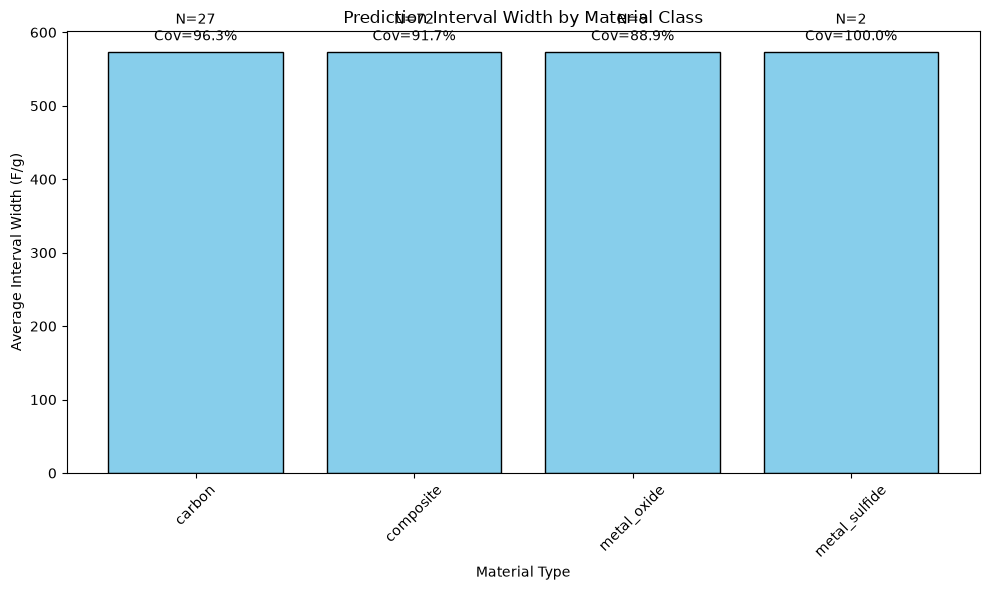

In [51]:
# ---------------------------------------------------------
# Break down prediction interval coverage and average width
# by material type on the random-split test set to identify
# which electrode families have higher or lower uncertainty.
# ---------------------------------------------------------

from IPython.display import display   
# =========================================================
# MATERIAL-WISE UNCERTAINTY ANALYSIS (Test Set)
# =========================================================
# Analyze on the Random Split Test Set
df_test_uq = X_test_full.copy()
df_test_uq['True_Y'] = y_test_full
df_test_uq['Pred_Y'] = preds_test_rand
df_test_uq['Lower_Bound'] = lb_rand
df_test_uq['Upper_Bound'] = ub_rand
df_test_uq['Interval_Width'] = widths_rand
df_test_uq['Coverage'] = (df_test_uq['True_Y'] >= df_test_uq['Lower_Bound']) & (df_test_uq['True_Y'] <= df_test_uq['Upper_Bound'])

material_analysis = df_test_uq.groupby('material_type').agg(
    N=('True_Y', 'count'),
    Coverage=('Coverage', 'mean'),
    Avg_Interval_Width=('Interval_Width', 'mean')
).reset_index()

material_analysis['Coverage'] = material_analysis['Coverage'] * 100

print("\n===== MATERIAL-WISE UNCERTAINTY (Random Split) =====")
display(material_analysis)

# Plotting Material-wise Width
plt.figure(figsize=(10, 6))
bars = plt.bar(material_analysis['material_type'], material_analysis['Avg_Interval_Width'], color='skyblue', edgecolor='black')
plt.ylabel('Average Interval Width (F/g)')
plt.xlabel('Material Type')
plt.title('Prediction Interval Width by Material Class')
plt.xticks(rotation=45)

# Annotate with N samples
for bar, n, cov in zip(bars, material_analysis['N'], material_analysis['Coverage']):
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 10, f"N={n}\nCov={cov:.1f}%", ha='center', va='bottom', fontsize=10)
    
plt.tight_layout()
plt.show()

